# M/PH/1 Stationary Performance Experiment — Revised Optimized Protocol

This notebook is the streamlined M/PH/1 continuation of the earlier M/GI/1 stationary experiment.

**Current experimental decision**

- The simulation protocol is **inherited** from the earlier experiment rather than re-selected here:
  - 30 independent replications per configuration;
  - 10,000 time units warm-up;
  - 40,000 time units recording.
- The formal ML dataset starts directly at the **same selected 300 configurations used by M/GI/1** (same $(\rho,\mathrm{SCV})$ points and split roles).
- Random-number streams are generated from a collision-free configuration `stream_id`; formal train/validation/test replications therefore use distinct integer seeds.
- A small **protocol-transfer validation** is retained only to verify that the PH service generator behaves correctly under the inherited settings.
- The PH generator is also checked empirically through $\hat\lambda$, $\widehat{E[S]}$, and $\widehat{\mathrm{SCV}}_S$.
- The primary ML target remains mean steady-state waiting time in queue, $W_q$.
- $L_q$ is **not trained as a separate ML target**; it is derived from predicted $W_q$ using Little's Law, $\widehat L_q=\lambda\widehat W_q$.

This keeps M/GI/1 and M/PH/1 comparable while avoiding repeated design-selection experiments already completed earlier.
> **Important:** the random-seed scheme has been changed to remove a train/test seed collision. Therefore previous downstream simulation/ML outputs are intentionally not reused. Run **Restart & Run All** once to regenerate the formal outputs under the revised seed streams.

**Additional regime-specific analysis**

- Sections 11--13 retain the completed combined M/PH/1 experiment and add
  separate \(SCV_S<1\) and \(SCV_S>1\) 300-configuration ML experiments.
- \(SCV_S=1\) is handled as an exponential / M/M/1 consistency boundary rather
  than as a third 300-configuration ML dataset.


## 1. Setup and inherited experimental protocol

In [1]:
from pathlib import Path
import json
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t as student_t
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# ------------------------------------------------------------
# Queue / reproducibility settings
# ------------------------------------------------------------
SERVICE_MEAN = 1.0
BASE_SEED = 123

# Inherited protocol from the established M/GI/1 experiment.
N_REPLICATIONS = 30
SIM_WARMUP_TIME = 10_000.0
SIM_RECORD_TIME = 40_000.0

# Small protocol-transfer check only; NOT a new window-selection pilot.
CHECK_RHOS = [0.30, 0.70, 0.95]
CHECK_SCVS = [0.25, 1.00, 2.00]

# Formal ML design is fixed in advance at 300 configurations.
N_CONFIGURATIONS_TARGET = 300
N_VALIDATION = 30
N_TEST = 30
N_TRAIN = N_CONFIGURATIONS_TARGET - N_VALIDATION - N_TEST

OUTPUT_DIR = Path("MPH1_outputs_SCV_updates")
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. PH service construction and exact M/PH/1 benchmark

For an M/PH/1 queue, the service time is represented by a phase-type pair $(\boldsymbol{\alpha},T)$.

The first two PH moments are
$$
E[S]=\boldsymbol{\alpha}(-T)^{-1}\mathbf 1,
\qquad
E[S^2]=2\boldsymbol{\alpha}(-T)^{-2}\mathbf 1.
$$

Because M/PH/1 is a special case of M/G/1, the Pollaczek–Khinchine mean waiting-time formula remains valid:
$$
W_q=\frac{\lambda E[S^2]}{2(1-\rho)}.
$$

With $E[S]=1$, $\lambda=\rho$. The PH matrices are still constructed explicitly so that this experiment genuinely uses a phase-type service representation.

In [2]:
def build_ph_distribution(service_mean, service_scv, tol=1e-12):
    """Construct a moment-matched PH distribution.

    Returns a dictionary containing alpha, T, family, and phase_count.

    Construction
    ------------
    SCV < 1:
        Sequential generalized-Erlang / hypoexponential PH distribution.
        The number of phases is k = ceil(1/SCV). One phase mean is allowed
        to differ so that both the requested mean and SCV are matched exactly.
    SCV = 1:
        One-phase exponential distribution.
    SCV > 1:
        Two-branch balanced-means hyperexponential distribution (H2),
        moment-matched to the requested mean and SCV.
    """
    if service_mean <= 0:
        raise ValueError("service_mean must be positive")
    if service_scv <= 0:
        raise ValueError("service_scv must be positive")

    m = float(service_mean)
    c2 = float(service_scv)

    # --------------------------------------------------------
    # Exponential PH: one transient phase
    # --------------------------------------------------------
    if abs(c2 - 1.0) <= tol:
        rate = 1.0 / m
        alpha = np.array([1.0], dtype=float)
        T = np.array([[-rate]], dtype=float)
        family = "exponential"

    # --------------------------------------------------------
    # Under-dispersed service: sequential PH
    # --------------------------------------------------------
    elif c2 < 1.0:
        # The smallest k such that 1/k <= c2.
        k = int(math.ceil((1.0 / c2) - 1e-12))
        k = max(k, 2)
        n = k - 1

        # Let the first n phase means be a and the last phase mean be b.
        # Solve n*a + b = m and n*a^2 + b^2 = c2*m^2.
        disc = n * ((n + 1) * c2 - 1.0)
        disc = max(disc, 0.0)
        x = (n - math.sqrt(disc)) / (n * (n + 1))
        a = m * x
        b = m * (1.0 - n * x)

        if a <= 0 or b <= 0:
            raise RuntimeError(
                f"Failed to construct positive sequential PH means for SCV={c2}."
            )

        phase_means = np.array([a] * n + [b], dtype=float)
        rates = 1.0 / phase_means

        alpha = np.zeros(k, dtype=float)
        alpha[0] = 1.0
        T = np.zeros((k, k), dtype=float)
        for i, rate in enumerate(rates):
            T[i, i] = -rate
            if i < k - 1:
                T[i, i + 1] = rate

        family = "generalized_erlang"

    # --------------------------------------------------------
    # Over-dispersed service: hyperexponential H2
    # --------------------------------------------------------
    else:
        p = 0.5 * (1.0 + math.sqrt((c2 - 1.0) / (c2 + 1.0)))
        rate_1 = 2.0 * p / m
        rate_2 = 2.0 * (1.0 - p) / m

        alpha = np.array([p, 1.0 - p], dtype=float)
        T = np.diag([-rate_1, -rate_2]).astype(float)
        family = "hyperexponential_2"

    return {
        "alpha": alpha,
        "T": T,
        "family": family,
        "phase_count": int(len(alpha)),
    }


def ph_moments(alpha, T):
    """Return the first two moments, variance, and SCV from (alpha, T)."""
    alpha = np.asarray(alpha, dtype=float)
    T = np.asarray(T, dtype=float)

    if T.ndim != 2 or T.shape[0] != T.shape[1]:
        raise ValueError("T must be a square matrix")
    if alpha.ndim != 1 or len(alpha) != T.shape[0]:
        raise ValueError("alpha length must match T dimension")
    if np.any(alpha < -1e-12) or not np.isclose(alpha.sum(), 1.0):
        raise ValueError("alpha must be a probability vector")

    ones = np.ones(T.shape[0])
    minus_T = -T

    # (-T)^(-1) 1
    first_vector = np.linalg.solve(minus_T, ones)
    # 2(-T)^(-2) 1
    second_vector = 2.0 * np.linalg.solve(minus_T, first_vector)

    mean = float(alpha @ first_vector)
    second_moment = float(alpha @ second_vector)
    variance = second_moment - mean**2
    scv = variance / mean**2

    return {
        "mean": mean,
        "variance": variance,
        "second_moment": second_moment,
        "scv": scv,
    }


def mph1_theory(rho, service_scv, service_mean=1.0):
    """Exact PK mean benchmark for the moment-matched M/PH/1 configuration."""
    if not (0 < rho < 1):
        raise ValueError("Stable M/PH/1 requires 0 < rho < 1")

    ph = build_ph_distribution(
        service_mean=service_mean,
        service_scv=service_scv,
    )
    moments = ph_moments(ph["alpha"], ph["T"])

    lam = rho / moments["mean"]
    wq = lam * moments["second_moment"] / (2.0 * (1.0 - rho))
    w = wq + moments["mean"]
    lq = lam * wq
    l = lam * w

    return {
        "rho": float(rho),
        "lambda_rate": float(lam),
        "service_mean": float(moments["mean"]),
        "service_scv": float(moments["scv"]),
        "service_second_moment": float(moments["second_moment"]),
        "ph_family": ph["family"],
        "ph_phase_count": ph["phase_count"],
        "Wq_theory": float(wq),
        "W_theory": float(w),
        "Lq_theory": float(lq),
        "L_theory": float(l),
    }


def ph_profile_record(service_mean, service_scv):
    """Serializable PH profile for tables/CSV design files."""
    ph = build_ph_distribution(service_mean, service_scv)
    moments = ph_moments(ph["alpha"], ph["T"])
    return {
        "ph_family": ph["family"],
        "ph_phase_count": ph["phase_count"],
        "ph_alpha": json.dumps(ph["alpha"].tolist()),
        "ph_T": json.dumps(ph["T"].tolist()),
        "ph_mean_check": moments["mean"],
        "ph_scv_check": moments["scv"],
    }

### 2.1 PH construction sanity check

In [3]:
ph_check_rows = []

for scv in CHECK_SCVS:
    ph = build_ph_distribution(SERVICE_MEAN, scv)
    moments = ph_moments(ph["alpha"], ph["T"])
    ph_check_rows.append({
        "requested_scv": scv,
        "family": ph["family"],
        "phase_count": ph["phase_count"],
        "mean_from_alpha_T": moments["mean"],
        "scv_from_alpha_T": moments["scv"],
        "alpha": ph["alpha"].tolist(),
        "T": ph["T"].tolist(),
    })

ph_check = pd.DataFrame(ph_check_rows)

assert np.allclose(ph_check["mean_from_alpha_T"], SERVICE_MEAN)
assert np.allclose(ph_check["scv_from_alpha_T"], ph_check["requested_scv"])

display(ph_check)

,requested_scv,family,phase_count,mean_from_alpha_T,scv_from_alpha_T,alpha,T
0,0.25,generalized_erlang,4,1.0,0.25,"[1.0, 0.0, 0.0, 0.0]","[[-4.0, 4.0, 0.0, 0.0], [0.0, -4.0, 4.0, 0.0],..."
1,1.00,exponential,1,1.0,1.00,[1.0],[[-1.0]]
2,2.00,hyperexponential_2,2,1.0,2.00,"[0.7886751345948129, 0.21132486540518713]","[[-1.5773502691896257, 0.0], [0.0, -0.42264973..."


## 3. Fixed-time M/PH/1 simulator

In [4]:
def generate_poisson_arrivals_until(rng, lambda_rate, end_time):
    """Generate exponential interarrival times until end_time."""
    expected = lambda_rate * end_time
    n_initial = max(
        100,
        int(expected + 12.0 * math.sqrt(max(expected, 1.0)) + 100)
    )

    interarrival = rng.exponential(
        scale=1.0 / lambda_rate,
        size=n_initial
    )
    arrivals = np.cumsum(interarrival)

    while arrivals[-1] < end_time:
        batch_size = max(100, int(0.05 * n_initial))
        extra = rng.exponential(
            scale=1.0 / lambda_rate,
            size=batch_size
        )
        arrivals = np.concatenate([
            arrivals,
            arrivals[-1] + np.cumsum(extra)
        ])

    return arrivals[arrivals < end_time]


def sample_ph_service_times(rng, ph, size):
    """Fast vectorised sampler for the PH constructions used in this notebook."""
    family = ph["family"]
    alpha = np.asarray(ph["alpha"], dtype=float)
    T = np.asarray(ph["T"], dtype=float)
    rates = -np.diag(T)

    if family == "exponential":
        return rng.exponential(scale=1.0 / rates[0], size=size)

    if family == "generalized_erlang":
        # The construction has k-1 equal phase means plus one final phase.
        # Sampling the equal-rate phases as one Gamma draw is equivalent to
        # summing those exponentials and is substantially faster.
        k = len(rates)
        if np.allclose(rates, rates[0]):
            return rng.gamma(
                shape=k,
                scale=1.0 / rates[0],
                size=size,
            )

        n_equal = k - 1
        service = rng.gamma(
            shape=n_equal,
            scale=1.0 / rates[0],
            size=size,
        )
        service += rng.exponential(
            scale=1.0 / rates[-1],
            size=size,
        )
        return service

    if family == "hyperexponential_2":
        # Choose the initial branch according to alpha, then absorb from it.
        initial_phase = rng.choice(len(alpha), size=size, p=alpha)
        return rng.exponential(scale=1.0 / rates[initial_phase])

    raise ValueError(f"Unsupported PH family: {family}")


def simulate_mph1_fixed_time(
    rho,
    service_scv,
    service_mean=1.0,
    warmup_time=SIM_WARMUP_TIME,
    record_time=SIM_RECORD_TIME,
    seed=123,
):
    """Fixed-time M/PH/1 simulation returning one replication-level estimate."""
    if not (0 < rho < 1):
        raise ValueError("rho must lie in (0, 1)")

    rng = np.random.default_rng(seed)
    ph = build_ph_distribution(
        service_mean=service_mean,
        service_scv=service_scv,
    )
    moments = ph_moments(ph["alpha"], ph["T"])

    lambda_rate = rho / moments["mean"]
    horizon_end = warmup_time + record_time

    arrival_time = generate_poisson_arrivals_until(
        rng=rng,
        lambda_rate=lambda_rate,
        end_time=horizon_end,
    )
    n_customers = len(arrival_time)

    service_time = sample_ph_service_times(
        rng=rng,
        ph=ph,
        size=n_customers,
    )

    # Vectorised FCFS Lindley/departure recursion.
    cumulative_service = np.cumsum(service_time)
    cumulative_before = np.empty(n_customers)
    cumulative_before[0] = 0.0
    cumulative_before[1:] = cumulative_service[:-1]

    running_offset = np.maximum.accumulate(
        arrival_time - cumulative_before
    )
    departure_time = cumulative_service + running_offset
    service_start = departure_time - service_time

    waiting_time = service_start - arrival_time
    system_time = departure_time - arrival_time

    cohort = (
        (arrival_time >= warmup_time)
        & (arrival_time < horizon_end)
    )

    if cohort.sum() == 0:
        raise RuntimeError("No arrivals in recording cohort")

    cohort_service = service_time[cohort]
    cohort_wait = waiting_time[cohort]
    cohort_system = system_time[cohort]

    lambda_hat = cohort.sum() / record_time
    service_mean_hat = cohort_service.mean()
    service_var_hat = cohort_service.var(ddof=0)
    service_scv_hat = service_var_hat / service_mean_hat**2

    return {
        "Wq_sim": float(cohort_wait.mean()),
        "W_sim": float(cohort_system.mean()),
        "lambda_hat": float(lambda_hat),
        "service_mean_hat": float(service_mean_hat),
        "service_scv_hat": float(service_scv_hat),
        "ph_family": ph["family"],
        "ph_phase_count": ph["phase_count"],
        "n_record_arrivals": int(cohort.sum()),
        "n_generated_arrivals": int(n_customers),
    }

## 4. Replications, 95% confidence intervals, and configuration labels

In [5]:
def run_replications_for_config(
    config_id,
    rho,
    service_scv,
    stream_id,
    seed_namespace,
    replications=N_REPLICATIONS,
    warmup_time=SIM_WARMUP_TIME,
    record_time=SIM_RECORD_TIME,
    service_mean=SERVICE_MEAN,
    base_seed=BASE_SEED,
):
    """Run independent replications using collision-free integer seed streams.

    The pair (seed_namespace, stream_id) uniquely identifies a configuration
    stream. With rep < 1000, the construction below is injective for the
    ranges used in this notebook.
    """
    rows = []
    theory = mph1_theory(
        rho=rho,
        service_scv=service_scv,
        service_mean=service_mean,
    )

    stream_id = int(stream_id)
    seed_namespace = int(seed_namespace)
    if stream_id < 0 or seed_namespace < 0:
        raise ValueError("stream_id and seed_namespace must be non-negative")
    if replications >= 1000:
        raise ValueError("replications must be < 1000 for this seed scheme")

    for rep in range(replications):
        seed = (
            int(base_seed)
            + seed_namespace * 10_000_000
            + stream_id * 1_000
            + rep
        )
        if seed >= 2**32 - 1:
            raise ValueError("seed exceeds NumPy's 32-bit seed range")

        start = time.perf_counter()
        sim = simulate_mph1_fixed_time(
            rho=rho,
            service_scv=service_scv,
            service_mean=service_mean,
            warmup_time=warmup_time,
            record_time=record_time,
            seed=seed,
        )
        elapsed = time.perf_counter() - start

        rows.append({
            "config_id": config_id,
            "stream_id": stream_id,
            "seed_namespace": seed_namespace,
            "rho": rho,
            "lambda_rate": theory["lambda_rate"],
            "service_mean": theory["service_mean"],
            "service_scv": theory["service_scv"],
            "ph_family": theory["ph_family"],
            "ph_phase_count": theory["ph_phase_count"],
            "warmup_time": warmup_time,
            "record_time": record_time,
            "replication": rep + 1,
            "seed": seed,
            "runtime_seconds": elapsed,
            "Wq_theory": theory["Wq_theory"],
            "Lq_theory": theory["Lq_theory"],
            **sim,
        })

    return pd.DataFrame(rows)


# W_q_sim is the simulated label; L_q is derived from W_q by Little's Law.
def aggregate_configuration_labels(replication_df):
    rows = []

    group_cols = [
        "config_id", "rho", "lambda_rate",
        "service_mean", "service_scv",
        "ph_family", "ph_phase_count",
        "warmup_time", "record_time",
    ]

    for keys, g in replication_df.groupby(group_cols, sort=True):
        (
            config_id, rho, lambda_rate, service_mean,
            service_scv, ph_family, ph_phase_count,
            warmup_time, record_time
        ) = keys

        wq = g["Wq_sim"].to_numpy(dtype=float)
        R = len(wq)
        mean = float(wq.mean())
        sd = float(wq.std(ddof=1)) if R > 1 else np.nan
        se = sd / math.sqrt(R) if R > 1 else np.nan
        tcrit = float(student_t.ppf(0.975, df=R-1)) if R > 1 else np.nan
        hw = tcrit * se if R > 1 else np.nan

        wq_theory = float(g["Wq_theory"].iloc[0])
        lq_theory = float(g["Lq_theory"].iloc[0])

        row = {
            "config_id": config_id,
            "rho": float(rho),
            "lambda_rate": float(lambda_rate),
            "service_mean": float(service_mean),
            "service_scv": float(service_scv),
            "ph_family": ph_family,
            "ph_phase_count": int(ph_phase_count),
            "warmup_time": float(warmup_time),
            "record_time": float(record_time),
            "n_replications": int(R),
            "Wq_theory": wq_theory,
            "Wq_sim_mean": mean,
            "Wq_rep_sd": sd,
            "Wq_se": se,
            "Wq_ci95_low": mean - hw,
            "Wq_ci95_high": mean + hw,
            "Wq_ci95_halfwidth": hw,
            "Wq_relative_ci_halfwidth_pct": (
                100.0 * hw / abs(mean) if mean != 0 else np.nan
            ),
            "Wq_abs_error_vs_theory": abs(mean - wq_theory),
            "Wq_rel_error_vs_theory_pct": (
                100.0 * abs(mean - wq_theory) / abs(wq_theory)
                if wq_theory != 0 else np.nan
            ),
            "Lq_theory": lq_theory,
            "Lq_derived_from_Wq": float(lambda_rate * mean),
            "Lq_ci95_low_derived": float(lambda_rate * (mean - hw)),
            "Lq_ci95_high_derived": float(lambda_rate * (mean + hw)),
            "lambda_hat_mean": float(g["lambda_hat"].mean()),
            "service_mean_hat_mean": float(g["service_mean_hat"].mean()),
            "service_scv_hat_mean": float(g["service_scv_hat"].mean()),
            "mean_runtime_seconds_per_rep": float(g["runtime_seconds"].mean()),
        }
        rows.append(row)

    return pd.DataFrame(rows)

## 5. Protocol-transfer validation

This is **not** a repeat of the earlier recording-window pilot.

The warm-up, recording horizon, and number of replications are already fixed by the established protocol. This small \(3\times3\) check only asks whether replacing the previous service generator with an explicit PH generator still produces stationary \(W_q\) estimates consistent with the exact PK benchmark, including difficult high-utilisation / high-variability cases.

In [6]:
check_configs = (
    pd.MultiIndex.from_product(
        [CHECK_RHOS, CHECK_SCVS],
        names=["rho", "service_scv"],
    )
    .to_frame(index=False)
)

check_configs.insert(
    0,
    "config_id",
    [
        f"check_rho{rho:.2f}_scv{scv:.2f}"
        for rho, scv in zip(check_configs["rho"], check_configs["service_scv"])
    ],
)

# Independent namespace for the small protocol-transfer check.
check_configs["stream_id"] = np.arange(len(check_configs), dtype=int)
CHECK_SEED_NAMESPACE = 1

check_frames = []

for _, cfg in check_configs.iterrows():
    print(
        f"Check {cfg['config_id']}: "
        f"rho={cfg['rho']:.2f}, SCV={cfg['service_scv']:.2f}"
    )
    check_frames.append(
        run_replications_for_config(
            config_id=cfg["config_id"],
            rho=float(cfg["rho"]),
            service_scv=float(cfg["service_scv"]),
            stream_id=int(cfg["stream_id"]),
            seed_namespace=CHECK_SEED_NAMESPACE,
            replications=N_REPLICATIONS,
            warmup_time=SIM_WARMUP_TIME,
            record_time=SIM_RECORD_TIME,
        )
    )

check_replications = pd.concat(check_frames, ignore_index=True)
assert check_replications["seed"].is_unique
check_labels = aggregate_configuration_labels(check_replications)
check_labels["CI_contains_theory"] = (
    (check_labels["Wq_ci95_low"] <= check_labels["Wq_theory"])
    & (check_labels["Wq_theory"] <= check_labels["Wq_ci95_high"])
)

check_replications.to_csv(
    OUTPUT_DIR / "mph1_protocol_transfer_check_replications.csv",
    index=False,
)
check_labels.to_csv(
    OUTPUT_DIR / "mph1_protocol_transfer_check_labels.csv",
    index=False,
)

display(
    check_labels[
        [
            "rho",
            "service_scv",
            "Wq_theory",
            "Wq_sim_mean",
            "Wq_ci95_low",
            "Wq_ci95_high",
            "Wq_rel_error_vs_theory_pct",
            "Wq_relative_ci_halfwidth_pct",
            "CI_contains_theory",
        ]
    ].sort_values(["rho", "service_scv"]).round(4)
)

Check check_rho0.30_scv0.25: rho=0.30, SCV=0.25
Check check_rho0.30_scv1.00: rho=0.30, SCV=1.00
Check check_rho0.30_scv2.00: rho=0.30, SCV=2.00
Check check_rho0.70_scv0.25: rho=0.70, SCV=0.25
Check check_rho0.70_scv1.00: rho=0.70, SCV=1.00
Check check_rho0.70_scv2.00: rho=0.70, SCV=2.00
Check check_rho0.95_scv0.25: rho=0.95, SCV=0.25
Check check_rho0.95_scv1.00: rho=0.95, SCV=1.00
Check check_rho0.95_scv2.00: rho=0.95, SCV=2.00


,rho,service_scv,Wq_theory,Wq_sim_mean,Wq_ci95_low,Wq_ci95_high,Wq_rel_error_vs_theory_pct,Wq_relative_ci_halfwidth_pct,CI_contains_theory
0,0.30,0.25,0.2679,0.2681,0.2650,0.2712,0.0899,1.1408,True
1,0.30,1.00,0.4286,0.4296,0.4230,0.4362,0.2364,1.5335,True
2,0.30,2.00,0.6429,0.6423,0.6243,0.6603,0.0890,2.7993,True
3,0.70,0.25,1.4583,1.4754,1.4590,1.4918,1.1704,1.1127,False
4,0.70,1.00,2.3333,2.3522,2.3031,2.4014,0.8093,2.0894,True
5,0.70,2.00,3.5000,3.5272,3.4369,3.6175,0.7777,2.5600,True
6,0.95,0.25,11.8750,12.0488,11.2725,12.8252,1.4639,6.4435,True
7,0.95,1.00,19.0000,19.4004,17.9310,20.8698,2.1073,7.5741,True
8,0.95,2.00,28.5000,26.9720,24.9446,28.9995,5.3614,7.5169,True


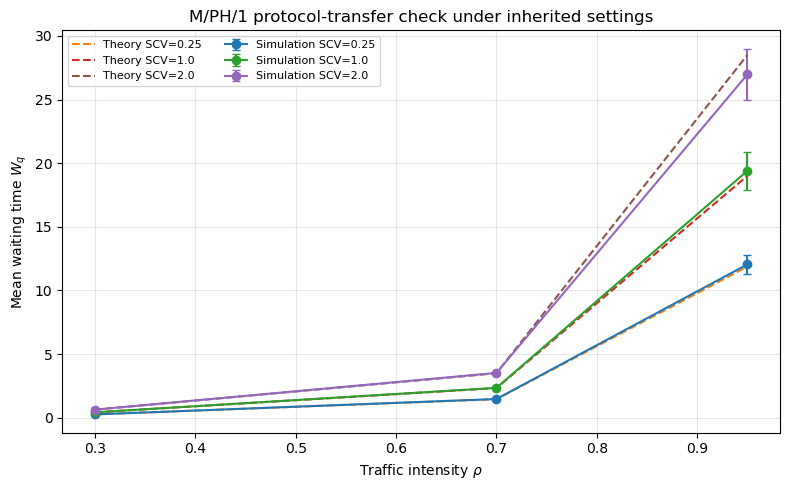

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

for scv in CHECK_SCVS:
    tmp = check_labels[
        np.isclose(check_labels["service_scv"], scv)
    ].sort_values("rho")

    yerr = np.vstack([
        tmp["Wq_sim_mean"] - tmp["Wq_ci95_low"],
        tmp["Wq_ci95_high"] - tmp["Wq_sim_mean"],
    ])

    ax.errorbar(
        tmp["rho"],
        tmp["Wq_sim_mean"],
        yerr=yerr,
        marker="o",
        capsize=3,
        label=f"Simulation SCV={scv}",
    )
    ax.plot(
        tmp["rho"],
        tmp["Wq_theory"],
        linestyle="--",
        label=f"Theory SCV={scv}",
    )

ax.set_xlabel(r"Traffic intensity $\rho$")
ax.set_ylabel(r"Mean waiting time $W_q$")
ax.set_title("M/PH/1 protocol-transfer check under inherited settings")
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "mph1_protocol_transfer_check_Wq.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 6. Formal 300-configuration design — inherited from M/GI/1

The formal M/PH/1 experiment starts directly from the **300-configuration design already selected in the preceding M/GI/1 experiment**. The 200→300→400 adequacy study is **not repeated** here.

For a controlled comparison, the same \((\rho,\mathrm{SCV})\) configurations and the same train/validation/test roles are reconstructed:

- the original 200-point grid contributes 140 train + 30 validation + 30 test configurations;
- the same first batch of 100 additional training configurations used for the selected M/GI/1 300-design is added;
- the resulting formal M/PH/1 design is therefore 240 train + 30 validation + 30 untouched test configurations.

Only the service-time representation changes from the earlier experiment to PH. This is stronger comparability than merely using the same number of configurations.

In [8]:
# ============================================================
# Reconstruct exactly the selected M/GI/1 300-configuration design
# ============================================================

# ------------------------------------------------------------
# A. Original 200-point grid
# ------------------------------------------------------------
RHO_GRID_200 = np.array([
    0.30, 0.34, 0.37, 0.40, 0.44,
    0.47, 0.50, 0.54, 0.57, 0.60,
    0.64, 0.67, 0.70, 0.74, 0.77,
    0.80, 0.84, 0.87, 0.90, 0.95,
])

SCV_GRID_200 = np.array([
    0.25, 0.45, 0.65, 0.85, 1.00,
    1.15, 1.35, 1.55, 1.75, 2.00,
])

base_design = (
    pd.MultiIndex.from_product(
        [RHO_GRID_200, SCV_GRID_200],
        names=["rho", "service_scv"],
    )
    .to_frame(index=False)
)

base_design.insert(
    0,
    "config_id",
    [f"cfg_{i:03d}" for i in range(len(base_design))],
)

assert len(base_design) == 200

# Same coarse strata and same random seeds as the preceding experiment.
base_design["rho_band"] = pd.cut(
    base_design["rho"],
    bins=[0.299, 0.50, 0.70, 0.85, 0.951],
    labels=["low", "moderate", "high", "very_high"],
    include_lowest=True,
)
base_design["scv_band"] = pd.cut(
    base_design["service_scv"],
    bins=[0.249, 0.80, 1.40, 2.001],
    labels=["low", "moderate", "high"],
    include_lowest=True,
)
base_design["stratum"] = (
    base_design["rho_band"].astype(str)
    + "_"
    + base_design["scv_band"].astype(str)
)

base_train_val, base_test = train_test_split(
    base_design,
    test_size=30,
    random_state=BASE_SEED,
    stratify=base_design["stratum"],
)

base_train, base_validation = train_test_split(
    base_train_val,
    test_size=30,
    random_state=BASE_SEED + 1,
    stratify=base_train_val["stratum"],
)

base_design["split"] = ""
base_design.loc[
    base_design["config_id"].isin(base_train["config_id"]), "split"
] = "train"
base_design.loc[
    base_design["config_id"].isin(base_validation["config_id"]), "split"
] = "validation"
base_design.loc[
    base_design["config_id"].isin(base_test["config_id"]), "split"
] = "test"

base_design["design_batch"] = "original_200"

# ------------------------------------------------------------
# B. Reconstruct the same first 100 added training configurations
#    that formed the selected M/GI/1 300-design.
# ------------------------------------------------------------
DENSE_RHO_GRID = np.round(np.linspace(0.30, 0.95, 61), 4)
DENSE_SCV_GRID = np.round(np.linspace(0.25, 2.00, 36), 4)

candidate_pool = (
    pd.MultiIndex.from_product(
        [DENSE_RHO_GRID, DENSE_SCV_GRID],
        names=["rho", "service_scv"],
    )
    .to_frame(index=False)
)

existing_keys = set(
    zip(
        base_design["rho"].round(4),
        base_design["service_scv"].round(4),
    )
)

candidate_pool["pair_key"] = list(
    zip(
        candidate_pool["rho"].round(4),
        candidate_pool["service_scv"].round(4),
    )
)

candidate_pool = candidate_pool[
    ~candidate_pool["pair_key"].isin(existing_keys)
].copy()

candidate_pool["rho_band"] = pd.cut(
    candidate_pool["rho"],
    bins=[0.299, 0.50, 0.70, 0.85, 0.951],
    labels=["low", "moderate", "high", "very_high"],
    include_lowest=True,
)
candidate_pool["scv_band"] = pd.cut(
    candidate_pool["service_scv"],
    bins=[0.249, 0.80, 1.40, 2.001],
    labels=["low", "moderate", "high"],
    include_lowest=True,
)
candidate_pool["stratum"] = (
    candidate_pool["rho_band"].astype(str)
    + "_"
    + candidate_pool["scv_band"].astype(str)
)

# This reproduces the same nested draw used in M/GI/1.
extra_200, _ = train_test_split(
    candidate_pool,
    train_size=200,
    random_state=BASE_SEED + 1200,
    stratify=candidate_pool["stratum"],
)

extra_100_for_300, _ = train_test_split(
    extra_200,
    train_size=100,
    random_state=BASE_SEED + 1201,
    stratify=extra_200["stratum"],
)

extra_100_for_300 = extra_100_for_300.copy().reset_index(drop=True)
extra_100_for_300["config_id"] = [
    f"size_extra_{i:03d}" for i in range(len(extra_100_for_300))
]
extra_100_for_300["split"] = "train"
extra_100_for_300["design_batch"] = "add_for_300"

# ------------------------------------------------------------
# C. Formal inherited 300-design
# ------------------------------------------------------------
configuration_design = pd.concat(
    [
        base_design,
        extra_100_for_300[
            [
                "config_id",
                "rho",
                "service_scv",
                "rho_band",
                "scv_band",
                "stratum",
                "split",
                "design_batch",
            ]
        ],
    ],
    ignore_index=True,
)

assert len(configuration_design) == N_CONFIGURATIONS_TARGET
assert configuration_design["config_id"].is_unique

# Collision-free random-number stream identifiers.  These are independent
# of rho/SCV values, so no arithmetic cancellation can create duplicate seeds.
configuration_design["stream_id"] = np.arange(
    len(configuration_design), dtype=int
)
configuration_design["seed_namespace"] = 2
assert configuration_design["stream_id"].is_unique

configuration_design["service_mean"] = SERVICE_MEAN
configuration_design["lambda_rate"] = (
    configuration_design["rho"] / SERVICE_MEAN
)
configuration_design["warmup_time"] = SIM_WARMUP_TIME
configuration_design["record_time"] = SIM_RECORD_TIME

# Explicit PH representation for every inherited configuration.
ph_design_profiles = pd.DataFrame([
    ph_profile_record(SERVICE_MEAN, float(scv))
    for scv in configuration_design["service_scv"]
])
for col in ph_design_profiles.columns:
    configuration_design[col] = ph_design_profiles[col].to_numpy()

# Exact external benchmark.
theory_rows = [
    mph1_theory(
        rho=float(row.rho),
        service_scv=float(row.service_scv),
        service_mean=SERVICE_MEAN,
    )
    for row in configuration_design.itertuples(index=False)
]
theory_df = pd.DataFrame(theory_rows)
configuration_design["Wq_theory"] = theory_df["Wq_theory"].to_numpy()
configuration_design["Lq_theory"] = theory_df["Lq_theory"].to_numpy()

split_counts = configuration_design["split"].value_counts()

assert split_counts["train"] == N_TRAIN
assert split_counts["validation"] == N_VALIDATION
assert split_counts["test"] == N_TEST

configuration_design.to_csv(
    OUTPUT_DIR / "mph1_configuration_design_300_inherited.csv",
    index=False,
)

print(configuration_design["split"].value_counts())
print("\nDesign batches:")
print(configuration_design["design_batch"].value_counts())
display(configuration_design.head(12))

split
train         240
test           30
validation     30
Name: count, dtype: int64

Design batches:
design_batch
original_200    200
add_for_300     100
Name: count, dtype: int64


,config_id,rho,service_scv,rho_band,scv_band,stratum,split,design_batch,stream_id,seed_namespace,...,warmup_time,record_time,ph_family,ph_phase_count,ph_alpha,ph_T,ph_mean_check,ph_scv_check,Wq_theory,Lq_theory
0,cfg_000,0.30,0.25,low,low,low_low,train,original_200,0,2,...,10000.0,40000.0,generalized_erlang,4,"[1.0, 0.0, 0.0, 0.0]","[[-4.0, 4.0, 0.0, 0.0], [0.0, -4.0, 4.0, 0.0],...",1.0,0.25,0.267857,0.080357
1,cfg_001,0.30,0.45,low,low,low_low,train,original_200,1,2,...,10000.0,40000.0,generalized_erlang,3,"[1.0, 0.0, 0.0]","[[-5.15756368460741, 5.15756368460741, 0.0], [...",1.0,0.45,0.310714,0.093214
2,cfg_002,0.30,0.65,low,low,low_low,train,original_200,2,2,...,10000.0,40000.0,generalized_erlang,2,"[1.0, 0.0]","[[-4.422064450014761, 4.422064450014761], [0.0...",1.0,0.65,0.353571,0.106071
3,cfg_003,0.30,0.85,low,moderate,low_moderate,train,original_200,3,2,...,10000.0,40000.0,generalized_erlang,2,"[1.0, 0.0]","[[-12.244400176893839, 12.244400176893839], [0...",1.0,0.85,0.396429,0.118929
4,cfg_004,0.30,1.00,low,moderate,low_moderate,test,original_200,4,2,...,10000.0,40000.0,exponential,1,[1.0],[[-1.0]],1.0,1.00,0.428571,0.128571
5,cfg_005,0.30,1.15,low,moderate,low_moderate,train,original_200,5,2,...,10000.0,40000.0,hyperexponential_2,2,"[0.6320676359488435, 0.3679323640511565]","[[-1.264135271897687, 0.0], [0.0, -0.735864728...",1.0,1.15,0.460714,0.138214
6,cfg_006,0.30,1.35,low,moderate,low_moderate,train,original_200,6,2,...,10000.0,40000.0,hyperexponential_2,2,"[0.69296124624699, 0.30703875375301004]","[[-1.38592249249398, 0.0], [0.0, -0.6140775075...",1.0,1.35,0.503571,0.151071
7,cfg_007,0.30,1.55,low,high,low_high,train,original_200,7,2,...,10000.0,40000.0,hyperexponential_2,2,"[0.732210182006412, 0.26778981799358803]","[[-1.464420364012824, 0.0], [0.0, -0.535579635...",1.0,1.55,0.546429,0.163929
8,cfg_008,0.30,1.75,low,high,low_high,test,original_200,8,2,...,10000.0,40000.0,hyperexponential_2,2,"[0.7611164839335467, 0.2388835160664533]","[[-1.5222329678670934, 0.0], [0.0, -0.47776703...",1.0,1.75,0.589286,0.176786
9,cfg_009,0.30,2.00,low,high,low_high,train,original_200,9,2,...,10000.0,40000.0,hyperexponential_2,2,"[0.7886751345948129, 0.21132486540518713]","[[-1.5773502691896257, 0.0], [0.0, -0.42264973...",1.0,2.00,0.642857,0.192857


### 6.1 Inherited design coverage check

In [9]:
coverage = pd.crosstab(
    [configuration_design["rho_band"], configuration_design["scv_band"]],
    configuration_design["split"],
    dropna=False,
)
coverage.to_csv(OUTPUT_DIR / "mph1_configuration_split_coverage.csv")
display(coverage)

split               test  train  validation
rho_band  scv_band                         
low       low          3     26           3
          moderate     4     30           4
          high         3     26           3
moderate  low          3     22           3
          moderate     4     26           4
          high         3     22           3
high      low          2     16           2
          moderate     2     19           2
          high         2     16           2
very_high low          1     12           1
          moderate     2     13           2
          high         1     12           1

## 7. Generate the 300 configuration-level stationary labels

Each configuration is simulated with the inherited fixed-time protocol. The **training label** is the replication mean `Wq_sim_mean`.

The exact PK value is retained only as an external benchmark; it is not used as the training target.

`Lq_derived_from_Wq` is included only as a Little's-Law transformation and is **not an independent simulation target**.

In [10]:
def generate_full_replication_dataset(
    design_df,
    replications=N_REPLICATIONS,
    warmup_time=SIM_WARMUP_TIME,
    record_time=SIM_RECORD_TIME,
):
    frames = []
    start_all = time.perf_counter()

    for j, cfg in enumerate(design_df.itertuples(index=False), start=1):
        if j == 1 or j % 25 == 0 or j == len(design_df):
            print(
                f"[{j}/{len(design_df)}] {cfg.config_id} "
                f"rho={cfg.rho:.2f}, SCV={cfg.service_scv:.2f}"
            )

        frames.append(
            run_replications_for_config(
                config_id=cfg.config_id,
                rho=float(cfg.rho),
                service_scv=float(cfg.service_scv),
                stream_id=int(cfg.stream_id),
                seed_namespace=int(cfg.seed_namespace),
                replications=replications,
                warmup_time=warmup_time,
                record_time=record_time,
            )
        )

    full_replications = pd.concat(frames, ignore_index=True)
    full_replications = (
        full_replications
        .sort_values(["config_id", "replication"])
        .reset_index(drop=True)
    )

    expected_rows = len(design_df) * replications
    assert len(full_replications) == expected_rows
    assert not full_replications.duplicated(["config_id", "replication"]).any()
    assert full_replications["seed"].is_unique

    runtime_total = time.perf_counter() - start_all
    return full_replications, runtime_total


full_replications, full_simulation_runtime_seconds = (
    generate_full_replication_dataset(configuration_design)
)

# Formal experiment and protocol-transfer check use disjoint random streams.
assert set(full_replications["seed"]).isdisjoint(set(check_replications["seed"]))

full_replications.to_csv(
    OUTPUT_DIR / "mph1_full_300_replications.csv",
    index=False,
)

stationary_labels = aggregate_configuration_labels(full_replications)
stationary_labels = stationary_labels.merge(
    configuration_design[[
        "config_id", "split", "rho_band", "scv_band",
        "design_batch", "stream_id", "seed_namespace"
    ]],
    on="config_id",
    how="left",
    validate="one_to_one",
)

assert len(stationary_labels) == 300
assert stationary_labels["config_id"].is_unique

stationary_labels["CI_contains_theory"] = (
    (stationary_labels["Wq_ci95_low"] <= stationary_labels["Wq_theory"])
    & (stationary_labels["Wq_theory"] <= stationary_labels["Wq_ci95_high"])
)

stationary_labels.to_csv(
    OUTPUT_DIR / "mph1_stationary_300_labels.csv",
    index=False,
)

print(
    f"Full 300-configuration label generation completed in "
    f"{full_simulation_runtime_seconds/60:.2f} minutes."
)
display(stationary_labels.head())

[1/300] cfg_000 rho=0.30, SCV=0.25
[25/300] cfg_024 rho=0.37, SCV=1.00
[50/300] cfg_049 rho=0.44, SCV=2.00
[75/300] cfg_074 rho=0.54, SCV=1.00
[100/300] cfg_099 rho=0.60, SCV=2.00
[125/300] cfg_124 rho=0.70, SCV=1.00
[150/300] cfg_149 rho=0.77, SCV=2.00
[175/300] cfg_174 rho=0.87, SCV=1.00
[200/300] cfg_199 rho=0.95, SCV=2.00
[225/300] size_extra_024 rho=0.49, SCV=1.00
[250/300] size_extra_049 rho=0.91, SCV=1.70
[275/300] size_extra_074 rho=0.52, SCV=1.70
[300/300] size_extra_099 rho=0.92, SCV=1.40
Full 300-configuration label generation completed in 0.15 minutes.


,config_id,rho,lambda_rate,service_mean,service_scv,ph_family,ph_phase_count,warmup_time,record_time,n_replications,...,service_mean_hat_mean,service_scv_hat_mean,mean_runtime_seconds_per_rep,split,rho_band,scv_band,design_batch,stream_id,seed_namespace,CI_contains_theory
0,cfg_000,0.3,0.3,1.0,0.25,generalized_erlang,4,10000.0,40000.0,30,...,0.999039,0.251275,0.000499,train,low,low,original_200,0,2,True
1,cfg_001,0.3,0.3,1.0,0.45,generalized_erlang,3,10000.0,40000.0,30,...,1.002313,0.446770,0.000462,train,low,low,original_200,1,2,True
2,cfg_002,0.3,0.3,1.0,0.65,generalized_erlang,2,10000.0,40000.0,30,...,1.000381,0.649973,0.000436,train,low,low,original_200,2,2,True
3,cfg_003,0.3,0.3,1.0,0.85,generalized_erlang,2,10000.0,40000.0,30,...,0.997165,0.851999,0.000418,train,low,moderate,original_200,3,2,True
4,cfg_004,0.3,0.3,1.0,1.00,exponential,1,10000.0,40000.0,30,...,1.001319,1.002488,0.000359,test,low,moderate,original_200,4,2,True


### 7.1 Empirical input-process validation and simulator quality

The PH construction has already been checked analytically through $(\alpha,T)$. Here the **actually generated simulation inputs** are checked empirically using the replication-averaged arrival rate, service mean, and service SCV.

The stationary output validation is then summarised overall and by traffic-intensity band / PH family. This makes the expected increase in Monte Carlo uncertainty as $\rho\to1$ explicit without re-running a recording-window selection study.


In [11]:
# ============================================================
# 7.1A Empirical input-process validation
# ============================================================
stationary_labels["lambda_rel_error_pct"] = (
    100.0
    * (stationary_labels["lambda_hat_mean"] - stationary_labels["lambda_rate"]).abs()
    / stationary_labels["lambda_rate"].abs()
)
stationary_labels["service_mean_rel_error_pct"] = (
    100.0
    * (stationary_labels["service_mean_hat_mean"] - stationary_labels["service_mean"]).abs()
    / stationary_labels["service_mean"].abs()
)
stationary_labels["service_scv_rel_error_pct"] = (
    100.0
    * (stationary_labels["service_scv_hat_mean"] - stationary_labels["service_scv"]).abs()
    / stationary_labels["service_scv"].abs()
)

input_process_validation = pd.DataFrame([{
    "n_configurations": len(stationary_labels),
    "mean_lambda_rel_error_pct": stationary_labels["lambda_rel_error_pct"].mean(),
    "max_lambda_rel_error_pct": stationary_labels["lambda_rel_error_pct"].max(),
    "mean_service_mean_rel_error_pct": stationary_labels["service_mean_rel_error_pct"].mean(),
    "max_service_mean_rel_error_pct": stationary_labels["service_mean_rel_error_pct"].max(),
    "mean_service_scv_rel_error_pct": stationary_labels["service_scv_rel_error_pct"].mean(),
    "max_service_scv_rel_error_pct": stationary_labels["service_scv_rel_error_pct"].max(),
}])

input_by_family = (
    stationary_labels
    .groupby("ph_family", observed=True)
    .agg(
        n_configurations=("config_id", "size"),
        mean_lambda_target=("lambda_rate", "mean"),
        mean_lambda_hat=("lambda_hat_mean", "mean"),
        mean_service_mean_target=("service_mean", "mean"),
        mean_service_mean_hat=("service_mean_hat_mean", "mean"),
        mean_service_scv_target=("service_scv", "mean"),
        mean_service_scv_hat=("service_scv_hat_mean", "mean"),
        mean_lambda_rel_error_pct=("lambda_rel_error_pct", "mean"),
        mean_service_mean_rel_error_pct=("service_mean_rel_error_pct", "mean"),
        mean_service_scv_rel_error_pct=("service_scv_rel_error_pct", "mean"),
    )
    .reset_index()
)

input_process_validation.to_csv(
    OUTPUT_DIR / "mph1_input_process_validation_300.csv",
    index=False,
)
input_by_family.to_csv(
    OUTPUT_DIR / "mph1_input_process_validation_by_family.csv",
    index=False,
)

print("Empirical input-process validation (all 300 configurations):")
display(input_process_validation.round(4))
print("Empirical input-process validation by PH family:")
display(input_by_family.round(4))

# ============================================================
# 7.1B Stationary simulation quality
# ============================================================
def quality_summary(df):
    return pd.Series({
        "n_configurations": len(df),
        "mean_relative_error_pct": df["Wq_rel_error_vs_theory_pct"].mean(),
        "median_relative_error_pct": df["Wq_rel_error_vs_theory_pct"].median(),
        "p90_relative_error_pct": df["Wq_rel_error_vs_theory_pct"].quantile(0.90),
        "ci95_coverage_pct": 100.0 * df["CI_contains_theory"].mean(),
        "mean_relative_ci_halfwidth_pct": df["Wq_relative_ci_halfwidth_pct"].mean(),
    })

simulation_quality = quality_summary(stationary_labels).to_frame().T
simulation_quality_by_rho = (
    stationary_labels
    .groupby("rho_band", observed=True)
    .apply(quality_summary, include_groups=False)
    .reset_index()
)
simulation_quality_by_family = (
    stationary_labels
    .groupby("ph_family", observed=True)
    .apply(quality_summary, include_groups=False)
    .reset_index()
)

simulation_quality.to_csv(
    OUTPUT_DIR / "mph1_simulation_quality_300.csv",
    index=False,
)
simulation_quality_by_rho.to_csv(
    OUTPUT_DIR / "mph1_simulation_quality_by_rho_band.csv",
    index=False,
)
simulation_quality_by_family.to_csv(
    OUTPUT_DIR / "mph1_simulation_quality_by_ph_family.csv",
    index=False,
)

print("Overall simulation quality:")
display(simulation_quality.round(4))
print("Simulation quality by traffic-intensity band:")
display(simulation_quality_by_rho.round(4))
print("Simulation quality by PH family:")
display(simulation_quality_by_family.round(4))


Empirical input-process validation (all 300 configurations):


,n_configurations,mean_lambda_rel_error_pct,max_lambda_rel_error_pct,mean_service_mean_rel_error_pct,max_service_mean_rel_error_pct,mean_service_scv_rel_error_pct,max_service_scv_rel_error_pct
0,300,0.097,0.4419,0.0921,0.4512,0.2309,1.3262


Empirical input-process validation by PH family:


,ph_family,n_configurations,mean_lambda_target,mean_lambda_hat,mean_service_mean_target,mean_service_mean_hat,mean_service_scv_target,mean_service_scv_hat,mean_lambda_rel_error_pct,mean_service_mean_rel_error_pct,mean_service_scv_rel_error_pct
0,exponential,22,0.6150,0.6150,1.0,1.0004,1.0000,1.0002,0.0947,0.0816,0.1933
1,generalized_erlang,123,0.6243,0.6242,1.0,0.9999,0.5606,0.5606,0.0951,0.0664,0.1844
2,hyperexponential_2,155,0.6213,0.6213,1.0,1.0001,1.5468,1.5470,0.0989,0.1139,0.2732


Overall simulation quality:


,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,300.0,0.8273,0.6059,1.7262,95.3333,2.2113


Simulation quality by traffic-intensity band:


,rho_band,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,low,102.0,0.5886,0.4994,1.1935,97.0588,1.5521
1,moderate,90.0,0.6669,0.5288,1.4073,93.3333,1.6168
2,high,63.0,0.7832,0.5880,1.7338,96.8254,2.3394
3,very_high,45.0,1.7512,1.3300,3.1939,93.3333,4.7152


Simulation quality by PH family:


,ph_family,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,exponential,22.0,0.7628,0.5981,1.7014,100.0000,1.9884
1,generalized_erlang,123.0,0.7896,0.5390,1.6901,91.8699,1.8439
2,hyperexponential_2,155.0,0.8664,0.6593,1.7368,97.4194,2.5346


## 8. ML experiment: predict stationary $W_q$

### Primary prediction problem

$$
(\rho,\mathrm{SCV}_S)\longrightarrow \widehat W_q.
$$

All models use the same raw inputs $(\rho,\mathrm{SCV}_S)$. The PH family and phase count are retained in the data for interpretation, but they are not added as redundant predictors for this mean-$W_q$ task.

Hyperparameters are selected only on the 30 validation configurations. The 30 test configurations remain untouched until the final evaluation.

In [12]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    abs_error = np.abs(y_pred - y_true)
    rel_error_pct = 100.0 * abs_error / np.abs(y_true)

    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": rmse(y_true, y_pred),
        "R2": float(r2_score(y_true, y_pred)),
        "MAPE_pct": float(rel_error_pct.mean()),
        "Median_APE_pct": float(np.median(rel_error_pct)),
    }


def average_prediction_time(model, X, repeats=100):
    start = time.perf_counter()
    for _ in range(repeats):
        model.predict(X)
    return (time.perf_counter() - start) / repeats


feature_cols = ["rho", "service_scv"]
target_col = "Wq_sim_mean"

train_df = stationary_labels[stationary_labels["split"] == "train"].copy()
val_df = stationary_labels[stationary_labels["split"] == "validation"].copy()
test_df = stationary_labels[stationary_labels["split"] == "test"].copy()

assert len(train_df) == 240
assert len(val_df) == 30
assert len(test_df) == 30

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_val = val_df[feature_cols]
y_val = val_df[target_col].to_numpy()
X_test = test_df[feature_cols]

### 8.1 Validation-only hyperparameter selection

In [13]:
dt_candidates = [
    {"max_depth": 2, "min_samples_leaf": 1},
    {"max_depth": 3, "min_samples_leaf": 1},
    {"max_depth": 4, "min_samples_leaf": 1},
    {"max_depth": 5, "min_samples_leaf": 1},
    {"max_depth": 3, "min_samples_leaf": 2},
    {"max_depth": 4, "min_samples_leaf": 2},
    {"max_depth": 5, "min_samples_leaf": 2},
    {"max_depth": None, "min_samples_leaf": 2},
]

rf_candidates = [
    {"n_estimators": 300, "max_depth": 3, "min_samples_leaf": 1},
    {"n_estimators": 300, "max_depth": 3, "min_samples_leaf": 2},
    {"n_estimators": 300, "max_depth": 5, "min_samples_leaf": 1},
    {"n_estimators": 300, "max_depth": 5, "min_samples_leaf": 2},
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 2},
]

xgb_candidates = [
    {"n_estimators": 150, "max_depth": 2, "learning_rate": 0.03},
    {"n_estimators": 250, "max_depth": 2, "learning_rate": 0.03},
    {"n_estimators": 150, "max_depth": 2, "learning_rate": 0.05},
    {"n_estimators": 250, "max_depth": 2, "learning_rate": 0.05},
    {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.03},
    {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.03},
    {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.05},
    {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.05},
]


def fit_candidate(model_name, params):
    if model_name == "Decision Tree":
        return DecisionTreeRegressor(
            random_state=BASE_SEED,
            **params,
        )

    if model_name == "Random Forest":
        return RandomForestRegressor(
            random_state=BASE_SEED,
            n_jobs=-1,
            **params,
        )

    if model_name == "XGBoost":
        return XGBRegressor(
            objective="reg:squarederror",
            random_state=BASE_SEED,
            n_jobs=-1,
            subsample=1.0,
            colsample_bytree=1.0,
            **params,
        )

    raise ValueError(model_name)


def select_on_validation(model_name, candidates):
    rows = []

    for params in candidates:
        model = fit_candidate(model_name, params)
        start = time.perf_counter()
        model.fit(X_train, y_train)
        train_seconds = time.perf_counter() - start
        pred = model.predict(X_val)

        rows.append({
            **params,
            "validation_RMSE_vs_sim_label": rmse(y_val, pred),
            "training_seconds": train_seconds,
        })

    search = (
        pd.DataFrame(rows)
        .sort_values("validation_RMSE_vs_sim_label")
        .reset_index(drop=True)
    )
    return search.iloc[0].to_dict(), search


# Linear Regression is the untuned raw-input baseline.
lr_val = LinearRegression()
lr_val.fit(X_train, y_train)
lr_val_pred = lr_val.predict(X_val)

selected_settings = {
    "Linear Regression": {},
}

search_tables = {}

for model_name, candidates in [
    ("Decision Tree", dt_candidates),
    ("Random Forest", rf_candidates),
    ("XGBoost", xgb_candidates),
]:
    best, search = select_on_validation(model_name, candidates)
    selected_settings[model_name] = best
    search_tables[model_name] = search
    search.to_csv(
        OUTPUT_DIR / f"mph1_{model_name.lower().replace(' ', '_')}_validation_search.csv",
        index=False,
    )

def json_safe_setting(key, value):
    """Convert pandas/NumPy scalar settings to strict JSON values."""
    if pd.isna(value):
        return None
    if key in {"n_estimators", "max_depth", "min_samples_leaf"}:
        return int(value)
    if isinstance(value, (float, np.floating)):
        return float(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    return value


selected_settings_table = pd.DataFrame([
    {
        "Model": model_name,
        "selected_settings": (
            "raw rho + SCV; no tuning"
            if model_name == "Linear Regression"
            else json.dumps(
                {
                    k: json_safe_setting(k, v)
                    for k, v in settings.items()
                    if k not in {"validation_RMSE_vs_sim_label", "training_seconds"}
                },
                allow_nan=False,
            )
        ),
    }
    for model_name, settings in selected_settings.items()
])

selected_settings_table.to_csv(
    OUTPUT_DIR / "mph1_selected_settings_300.csv",
    index=False,
)

print("Linear Regression validation RMSE:", round(rmse(y_val, lr_val_pred), 6))
display(selected_settings_table)

for model_name, search in search_tables.items():
    print(f"\n{model_name} validation search:")
    display(search.round(6))

Linear Regression validation RMSE: 2.524307


,Model,selected_settings
0,Linear Regression,raw rho + SCV; no tuning
1,Decision Tree,"{""max_depth"": 5, ""min_samples_leaf"": 1}"
2,Random Forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_..."
3,XGBoost,"{""n_estimators"": 250, ""max_depth"": 3, ""learnin..."



Decision Tree validation search:


,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,5.0,1,0.560129,0.000432
1,4.0,1,0.692089,0.000498
2,NaN,2,0.996290,0.000341
3,5.0,2,1.065744,0.000296
4,4.0,2,1.118688,0.000292
5,3.0,1,1.307129,0.000634
6,3.0,2,1.307129,0.000299
7,2.0,1,2.224092,0.000818



Random Forest validation search:


,n_estimators,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,300,NaN,1,0.476058,0.095381
1,300,5.0,1,0.508425,0.104996
2,300,NaN,2,0.880554,0.096712
3,300,3.0,1,0.882105,0.117754
4,300,5.0,2,0.899061,0.097247
5,300,3.0,2,1.033095,0.127062



XGBoost validation search:


,n_estimators,max_depth,learning_rate,validation_RMSE_vs_sim_label,training_seconds
0,250,3,0.05,0.178378,0.027276
1,150,3,0.05,0.193437,0.057181
2,250,3,0.03,0.211905,0.032858
3,150,3,0.03,0.248372,0.019844
4,250,2,0.05,0.416501,0.023470
5,250,2,0.03,0.454194,0.020494
6,150,2,0.05,0.455939,0.012590
7,150,2,0.03,0.571120,0.016473


## 9. Final held-out evaluation

After hyperparameters are fixed, the 240 training and 30 validation configurations are combined into a 270-configuration development set. Each model is then refit once and evaluated on the untouched 30-configuration test set.

The primary metrics are reported for \(W_q\) against both:

1. the simulation mean label actually learned by the model; and
2. the exact PK benchmark.

\(L_q\) is derived afterward from \(\widehat W_q\); no separate \(L_q\) model is trained.

In [14]:
development_df = pd.concat([train_df, val_df], ignore_index=True)

X_dev = development_df[feature_cols]
y_dev = development_df[target_col]
y_test_sim = test_df[target_col].to_numpy()
y_test_theory = test_df["Wq_theory"].to_numpy()

assert len(development_df) == 270
assert set(development_df["config_id"]).isdisjoint(set(test_df["config_id"]))


def clean_selected_params(model_name, selected):
    if model_name == "Decision Tree":
        return {
            "max_depth": (
                None if pd.isna(selected["max_depth"])
                else int(selected["max_depth"])
            ),
            "min_samples_leaf": int(selected["min_samples_leaf"]),
        }

    if model_name == "Random Forest":
        return {
            "n_estimators": int(selected["n_estimators"]),
            "max_depth": (
                None if pd.isna(selected["max_depth"])
                else int(selected["max_depth"])
            ),
            "min_samples_leaf": int(selected["min_samples_leaf"]),
        }

    if model_name == "XGBoost":
        return {
            "n_estimators": int(selected["n_estimators"]),
            "max_depth": int(selected["max_depth"]),
            "learning_rate": float(selected["learning_rate"]),
        }

    return {}


final_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": fit_candidate(
        "Decision Tree",
        clean_selected_params(
            "Decision Tree", selected_settings["Decision Tree"]
        ),
    ),
    "Random Forest": fit_candidate(
        "Random Forest",
        clean_selected_params(
            "Random Forest", selected_settings["Random Forest"]
        ),
    ),
    "XGBoost": fit_candidate(
        "XGBoost",
        clean_selected_params(
            "XGBoost", selected_settings["XGBoost"]
        ),
    ),
}

final_predictions = {}
training_times = {}
prediction_times = {}

for model_name, model in final_models.items():
    start = time.perf_counter()
    model.fit(X_dev, y_dev)
    training_times[model_name] = time.perf_counter() - start

    final_predictions[model_name] = model.predict(X_test)
    prediction_times[model_name] = average_prediction_time(
        model, X_test, repeats=50
    )

metric_rows = []

for model_name, pred in final_predictions.items():
    metric_rows.append({
        "Model": model_name,
        "Reference": "simulation mean label",
        **regression_metrics(y_test_sim, pred),
    })
    metric_rows.append({
        "Model": model_name,
        "Reference": "PK theory",
        **regression_metrics(y_test_theory, pred),
    })

final_test_metrics = pd.DataFrame(metric_rows)
final_test_metrics.to_csv(
    OUTPUT_DIR / "mph1_final_300_test_metrics.csv",
    index=False,
)

timing = pd.DataFrame([
    {
        "Model": model_name,
        "training_seconds": training_times[model_name],
        "prediction_seconds_for_30_test_configs": prediction_times[model_name],
    }
    for model_name in final_models
])
timing.to_csv(
    OUTPUT_DIR / "mph1_final_300_timing.csv",
    index=False,
)

print("Final 300-configuration held-out test metrics:")
display(final_test_metrics.round(6))

print("Final model timing:")
display(timing.round(6))

Final 300-configuration held-out test metrics:


,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,simulation mean label,1.655162,2.212965,0.591867,113.682686,80.943255
1,Linear Regression,PK theory,1.639183,2.156127,0.598488,113.788858,81.230001
2,Decision Tree,simulation mean label,0.528615,0.861852,0.938096,20.394099,19.209174
3,Decision Tree,PK theory,0.506630,0.793817,0.945576,20.387494,19.188828
4,Random Forest,simulation mean label,0.186534,0.449617,0.983152,4.955187,2.609577
5,Random Forest,PK theory,0.173060,0.366534,0.988397,4.946015,3.397160
6,XGBoost,simulation mean label,0.126339,0.249548,0.994810,4.463201,3.019595
7,XGBoost,PK theory,0.092742,0.155816,0.997903,4.041699,2.655689


Final model timing:


,Model,training_seconds,prediction_seconds_for_30_test_configs
0,Linear Regression,0.000602,0.000140
1,Decision Tree,0.000846,0.000154
2,Random Forest,0.116352,0.013564
3,XGBoost,0.030265,0.000168


### 9.1 Configuration-level predictions and derived \(L_q\)

In [15]:
final_test_predictions = test_df[
    [
        "config_id",
        "rho",
        "lambda_rate",
        "service_scv",
        "ph_family",
        "ph_phase_count",
        "Wq_sim_mean",
        "Wq_theory",
        "Wq_ci95_low",
        "Wq_ci95_high",
        "Wq_relative_ci_halfwidth_pct",
        "Lq_theory",
        "Lq_derived_from_Wq",
    ]
].copy()

short_names = {
    "Linear Regression": "LR",
    "Decision Tree": "DT",
    "Random Forest": "RF",
    "XGBoost": "XGB",
}

for model_name, pred in final_predictions.items():
    short = short_names[model_name]

    # Primary ML prediction.
    final_test_predictions[f"Wq_pred_{short}"] = pred

    # Secondary derived quantity only — no separate Lq model is fitted.
    final_test_predictions[f"Lq_derived_pred_{short}"] = (
        final_test_predictions["lambda_rate"] * pred
    )

    final_test_predictions[
        f"Wq_abs_error_{short}_vs_theory"
    ] = (
        final_test_predictions[f"Wq_pred_{short}"]
        - final_test_predictions["Wq_theory"]
    ).abs()

    final_test_predictions[
        f"Wq_rel_error_pct_{short}_vs_theory"
    ] = (
        100.0
        * final_test_predictions[f"Wq_abs_error_{short}_vs_theory"]
        / final_test_predictions["Wq_theory"].abs()
    )

final_test_predictions.to_csv(
    OUTPUT_DIR / "mph1_final_300_test_predictions.csv",
    index=False,
)

display(final_test_predictions.head())

,config_id,rho,lambda_rate,service_scv,ph_family,ph_phase_count,Wq_sim_mean,Wq_theory,Wq_ci95_low,Wq_ci95_high,...,Wq_abs_error_DT_vs_theory,Wq_rel_error_pct_DT_vs_theory,Wq_pred_RF,Lq_derived_pred_RF,Wq_abs_error_RF_vs_theory,Wq_rel_error_pct_RF_vs_theory,Wq_pred_XGB,Lq_derived_pred_XGB,Wq_abs_error_XGB_vs_theory,Wq_rel_error_pct_XGB_vs_theory
4,cfg_004,0.30,0.30,1.00,exponential,1,0.430690,0.428571,0.425043,0.436338,...,0.363632,84.847464,0.463547,0.139064,0.034976,8.160989,0.492251,0.147675,0.063679,14.858464
8,cfg_008,0.30,0.30,1.75,hyperexponential_2,2,0.588503,0.589286,0.576977,0.600030,...,0.202918,34.434519,0.613819,0.184146,0.024534,4.163275,0.655816,0.196745,0.066531,11.290042
20,cfg_020,0.37,0.37,0.25,generalized_erlang,4,0.365113,0.367063,0.360504,0.369721,...,0.134020,36.511443,0.417438,0.154452,0.050375,13.723757,0.277066,0.102515,0.089997,24.518132
27,cfg_027,0.37,0.37,1.55,hyperexponential_2,2,0.750143,0.748810,0.738266,0.762019,...,0.043394,5.795051,0.753619,0.278839,0.004809,0.642259,0.780464,0.288772,0.031655,4.227346
41,cfg_041,0.44,0.44,0.45,generalized_erlang,3,0.577725,0.569643,0.570896,0.584554,...,0.068559,12.035468,0.572798,0.252031,0.003155,0.553829,0.569789,0.250707,0.000146,0.025664


### 9.2 Derived \(L_q\) diagnostic

This table is intentionally a **derived diagnostic**, not a second prediction experiment. Each row uses

\[
\widehat L_q=\lambda\widehat W_q.
\]

Therefore any \(L_q\) accuracy reported here is inherited from the corresponding \(W_q\) prediction.

In [16]:
lq_metric_rows = []

for model_name, short in short_names.items():
    lq_metric_rows.append({
        "Model": model_name,
        "Construction": "derived from Wq prediction via Little's Law",
        **regression_metrics(
            final_test_predictions["Lq_theory"].to_numpy(),
            final_test_predictions[f"Lq_derived_pred_{short}"].to_numpy(),
        ),
    })

derived_lq_metrics = pd.DataFrame(lq_metric_rows)
derived_lq_metrics.to_csv(
    OUTPUT_DIR / "mph1_derived_Lq_test_metrics.csv",
    index=False,
)

display(derived_lq_metrics.round(6))

,Model,Construction,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,derived from Wq prediction via Little's Law,1.103579,1.702593,0.722573,113.788858,81.230001
1,Decision Tree,derived from Wq prediction via Little's Law,0.389055,0.689961,0.954441,20.387494,19.188828
2,Random Forest,derived from Wq prediction via Little's Law,0.142856,0.333356,0.989365,4.946015,3.397160
3,XGBoost,derived from Wq prediction via Little's Law,0.072158,0.138026,0.998177,4.041699,2.655689


## 10. Final diagnostic plots

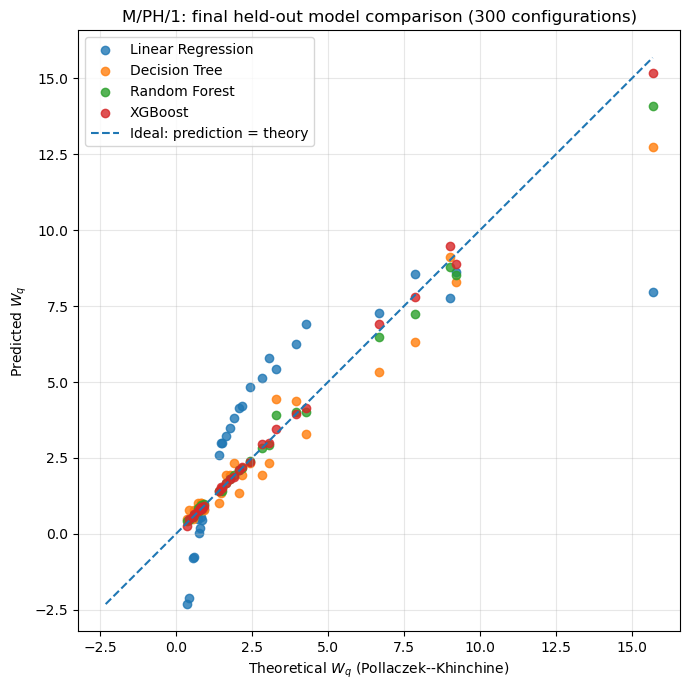

In [17]:
fig, ax = plt.subplots(figsize=(7, 7))

x = final_test_predictions["Wq_theory"]

for model_name, short in short_names.items():
    ax.scatter(
        x,
        final_test_predictions[f"Wq_pred_{short}"],
        label=model_name,
        alpha=0.8,
    )

pred_cols = [f"Wq_pred_{short}" for short in short_names.values()]

lo = min(x.min(), final_test_predictions[pred_cols].min().min())
hi = max(x.max(), final_test_predictions[pred_cols].max().max())

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    label="Ideal: prediction = theory",
)

ax.set_xlabel(r"Theoretical $W_q$ (Pollaczek--Khinchine)")
ax.set_ylabel(r"Predicted $W_q$")
ax.set_title("M/PH/1: final held-out model comparison (300 configurations)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "mph1_final_300_predicted_vs_theoretical_Wq.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

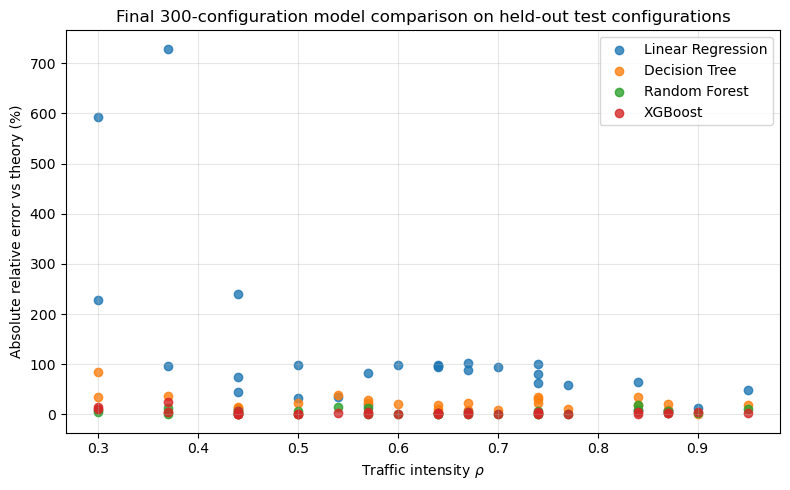

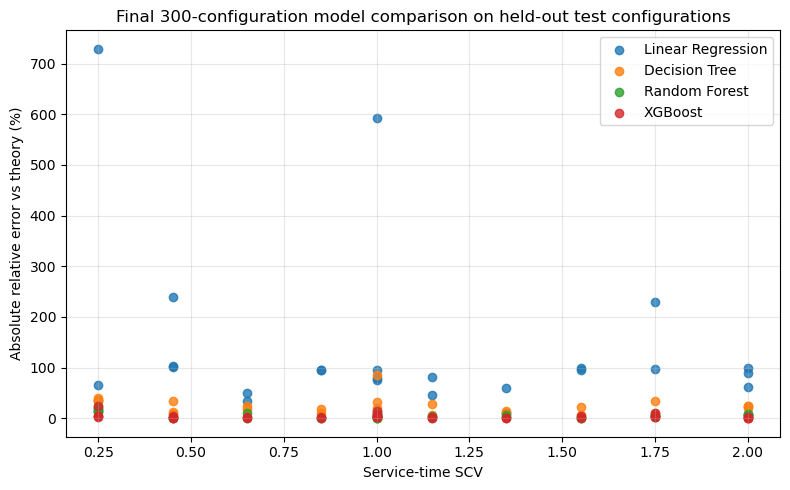

In [18]:
# ============================================================
# Primary cross-system comparison plots
# Match the final M/GI/1 plotting convention
# ============================================================

error_cols = {
    model_name: f"Wq_rel_error_pct_{short}_vs_theory"
    for model_name, short in short_names.items()
}

for x_col, x_label, filename in [
    (
        "rho",
        r"Traffic intensity $\rho$",
        "mph1_final_300_relative_error_vs_rho.png",
    ),
    (
        "service_scv",
        "Service-time SCV",
        "mph1_final_300_relative_error_vs_scv.png",
    ),
]:
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, error_col in error_cols.items():
        ax.scatter(
            final_test_predictions[x_col],
            final_test_predictions[error_col],
            label=model_name,
            alpha=0.8,
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs theory (%)")
    ax.set_title(
        "Final 300-configuration model comparison "
        "on held-out test configurations"
    )

    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

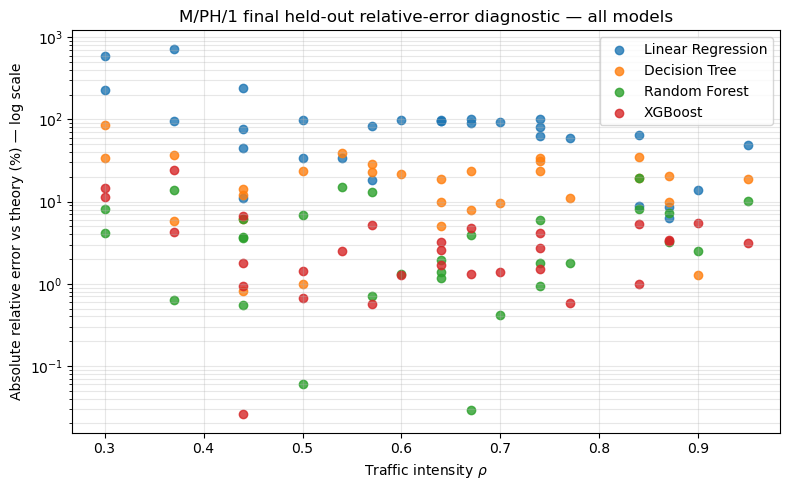

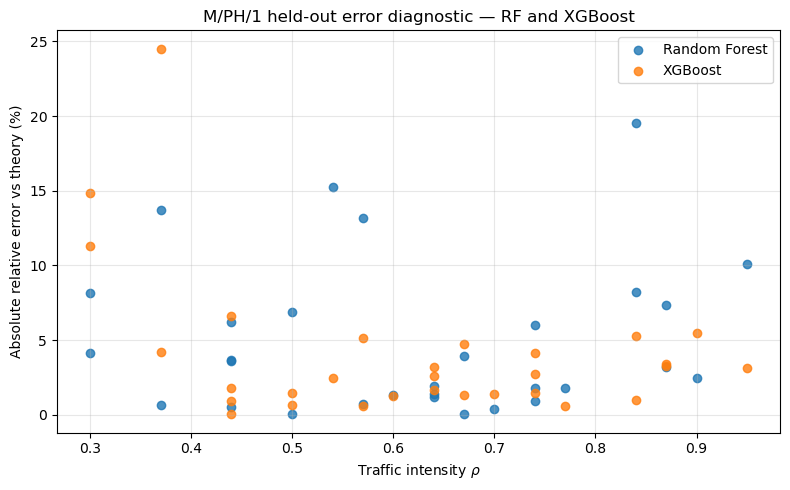

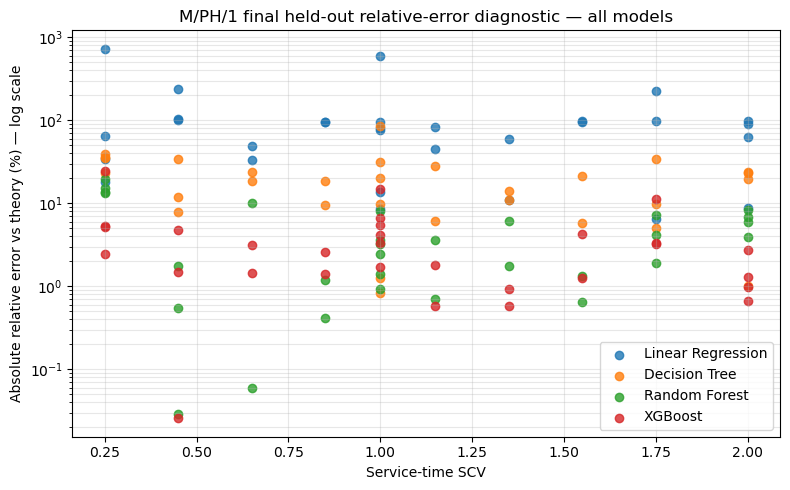

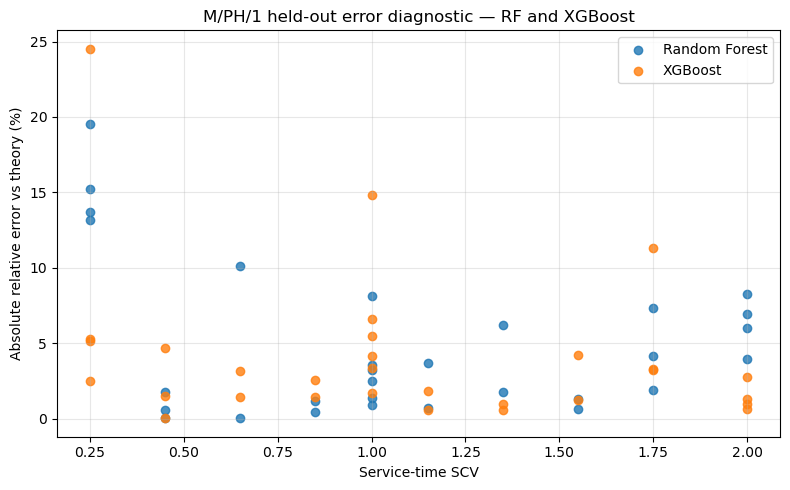

In [19]:
## supplementary diagnostic
error_cols = {
    model_name: f"Wq_rel_error_pct_{short}_vs_theory"
    for model_name, short in short_names.items()
}

for x_col, x_label, filename_stem in [
    ("rho", r"Traffic intensity $\rho$", "rho"),
    ("service_scv", "Service-time SCV", "scv"),
]:
    # --------------------------------------------------------
    # A. All models on a log y-axis, so large LR errors do not
    #    visually compress the stronger nonlinear models.
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, error_col in error_cols.items():
        y = np.clip(
            final_test_predictions[error_col].to_numpy(dtype=float),
            1e-3,
            None,
        )
        ax.scatter(
            final_test_predictions[x_col],
            y,
            label=model_name,
            alpha=0.8,
        )

    ax.set_yscale("log")
    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs theory (%) — log scale")
    ax.set_title("M/PH/1 final held-out relative-error diagnostic — all models")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"mph1_final_300_relative_error_vs_{filename_stem}_log.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    # --------------------------------------------------------
    # B. Focused linear-scale diagnostic for the two strongest
    #    ensemble models.
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name in ["Random Forest", "XGBoost"]:
        error_col = error_cols[model_name]
        ax.scatter(
            final_test_predictions[x_col],
            final_test_predictions[error_col],
            label=model_name,
            alpha=0.8,
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs theory (%)")
    ax.set_title("M/PH/1 held-out error diagnostic — RF and XGBoost")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"mph1_final_300_relative_error_vs_{filename_stem}_RF_XGB.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


## 11. Regime-specific M/PH/1 experiment: \(SCV_S < 1\)

This section adds a **separate low-SCV experiment** without changing the completed
combined M/PH/1 experiment in Sections 6--10.

The PH generator itself is unchanged. Because every configuration in this section
satisfies \(SCV_S<1\), `build_ph_distribution()` automatically uses the
**generalized-Erlang / sequential hypoexponential PH construction** for every
service-time distribution.

The experimental protocol is inherited from the established design:

- \(E[S]=1\);
- the same 20 utilisation values, \(0.30\leq\rho\leq0.95\);
- 30 independent replications per configuration;
- 10,000 warm-up + 40,000 recording time units;
- 300 configurations in total;
- 240 training + 30 validation + 30 held-out test configurations;
- the same LR / DT / RF / XGBoost comparison and validation-only model selection.

Unlike the combined experiment, this regime-specific experiment constructs the
300 configurations **directly** as \(20\) utilisation values \(\times\) \(15\)
low-SCV values. There is no 200+100 dataset-size construction because the earlier
M/GI/1 experiment already established 300 configurations as the working design size.


### 11.1 Direct 300-configuration low-SCV design


In [20]:
# ============================================================
# SCV < 1 experiment: direct 20 x 15 = 300 configuration grid
# ============================================================

SCV_LT1_RHO_GRID = RHO_GRID_200.copy()
SCV_LT1_GRID = np.round(np.linspace(0.25, 0.95, 15), 4)

scv_lt1_design = (
    pd.MultiIndex.from_product(
        [SCV_LT1_RHO_GRID, SCV_LT1_GRID],
        names=["rho", "service_scv"],
    )
    .to_frame(index=False)
)

scv_lt1_design.insert(
    0,
    "config_id",
    [f"lt1_cfg_{i:03d}" for i in range(len(scv_lt1_design))],
)

assert len(scv_lt1_design) == 300
assert scv_lt1_design["config_id"].is_unique
assert scv_lt1_design["service_scv"].lt(1.0).all()

# Stratification is adapted to the restricted SCV<1 range.
scv_lt1_design["rho_band"] = pd.cut(
    scv_lt1_design["rho"],
    bins=[0.299, 0.50, 0.70, 0.85, 0.951],
    labels=["low", "moderate", "high", "very_high"],
    include_lowest=True,
)
scv_lt1_design["scv_band"] = pd.cut(
    scv_lt1_design["service_scv"],
    bins=[0.249, 0.50, 0.75, 0.951],
    labels=["low_scv", "mid_scv", "near_1"],
    include_lowest=True,
)
scv_lt1_design["stratum"] = (
    scv_lt1_design["rho_band"].astype(str)
    + "_"
    + scv_lt1_design["scv_band"].astype(str)
)

# Separate split draw for this regime-specific experiment.
scv_lt1_train_val, scv_lt1_test = train_test_split(
    scv_lt1_design,
    test_size=N_TEST,
    random_state=BASE_SEED + 2100,
    stratify=scv_lt1_design["stratum"],
)

scv_lt1_train, scv_lt1_validation = train_test_split(
    scv_lt1_train_val,
    test_size=N_VALIDATION,
    random_state=BASE_SEED + 2101,
    stratify=scv_lt1_train_val["stratum"],
)

scv_lt1_design["split"] = ""
scv_lt1_design.loc[
    scv_lt1_design["config_id"].isin(scv_lt1_train["config_id"]), "split"
] = "train"
scv_lt1_design.loc[
    scv_lt1_design["config_id"].isin(scv_lt1_validation["config_id"]), "split"
] = "validation"
scv_lt1_design.loc[
    scv_lt1_design["config_id"].isin(scv_lt1_test["config_id"]), "split"
] = "test"

scv_lt1_design["design_batch"] = "scv_lt1_direct_300"

# Use a new namespace so this experiment has random streams disjoint from
# the protocol-transfer check and the completed combined M/PH/1 experiment.
scv_lt1_design["stream_id"] = np.arange(len(scv_lt1_design), dtype=int)
scv_lt1_design["seed_namespace"] = 11

scv_lt1_design["service_mean"] = SERVICE_MEAN
scv_lt1_design["lambda_rate"] = scv_lt1_design["rho"] / SERVICE_MEAN
scv_lt1_design["warmup_time"] = SIM_WARMUP_TIME
scv_lt1_design["record_time"] = SIM_RECORD_TIME

# Construct the PH representation for every configuration.
scv_lt1_ph_profiles = pd.DataFrame([
    ph_profile_record(SERVICE_MEAN, float(scv))
    for scv in scv_lt1_design["service_scv"]
])
for col in scv_lt1_ph_profiles.columns:
    scv_lt1_design[col] = scv_lt1_ph_profiles[col].to_numpy()

# Every distribution must be from the SCV<1 generalized-Erlang branch.
assert scv_lt1_design["ph_family"].eq("generalized_erlang").all()

# Exact PK benchmark.
scv_lt1_theory_rows = [
    mph1_theory(
        rho=float(row.rho),
        service_scv=float(row.service_scv),
        service_mean=SERVICE_MEAN,
    )
    for row in scv_lt1_design.itertuples(index=False)
]
scv_lt1_theory_df = pd.DataFrame(scv_lt1_theory_rows)
scv_lt1_design["Wq_theory"] = scv_lt1_theory_df["Wq_theory"].to_numpy()
scv_lt1_design["Lq_theory"] = scv_lt1_theory_df["Lq_theory"].to_numpy()

scv_lt1_split_counts = scv_lt1_design["split"].value_counts()
assert scv_lt1_split_counts["train"] == N_TRAIN
assert scv_lt1_split_counts["validation"] == N_VALIDATION
assert scv_lt1_split_counts["test"] == N_TEST

scv_lt1_design.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_configuration_design_300.csv",
    index=False,
)

scv_lt1_coverage = pd.crosstab(
    [scv_lt1_design["rho_band"], scv_lt1_design["scv_band"]],
    scv_lt1_design["split"],
    dropna=False,
)
scv_lt1_coverage.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_configuration_split_coverage.csv"
)

print("SCV<1 split counts:")
print(scv_lt1_split_counts)
print("\nSCV range:", scv_lt1_design["service_scv"].min(),
      "to", scv_lt1_design["service_scv"].max())
print("PH families:", scv_lt1_design["ph_family"].value_counts().to_dict())
display(scv_lt1_coverage)
display(scv_lt1_design.head(12))


SCV<1 split counts:
split
train         240
test           30
validation     30
Name: count, dtype: int64

SCV range: 0.25 to 0.95
PH families: {'generalized_erlang': 300}


split               test  train  validation
rho_band  scv_band                         
low       low_scv      4     34           4
          mid_scv      3     28           4
          near_1       3     22           3
moderate  low_scv      4     28           4
          mid_scv      3     24           3
          near_1       2     20           2
high      low_scv      2     20           2
          mid_scv      2     16           2
          near_1       2     12           2
very_high low_scv      2     14           2
          mid_scv      2     12           1
          near_1       1     10           1

,config_id,rho,service_scv,rho_band,scv_band,stratum,split,design_batch,stream_id,seed_namespace,...,warmup_time,record_time,ph_family,ph_phase_count,ph_alpha,ph_T,ph_mean_check,ph_scv_check,Wq_theory,Lq_theory
0,lt1_cfg_000,0.3,0.25,low,low_scv,low_low_scv,test,scv_lt1_direct_300,0,11,...,10000.0,40000.0,generalized_erlang,4,"[1.0, 0.0, 0.0, 0.0]","[[-4.0, 4.0, 0.0, 0.0], [0.0, -4.0, 4.0, 0.0],...",1.0,0.25,0.267857,0.080357
1,lt1_cfg_001,0.3,0.30,low,low_scv,low_low_scv,test,scv_lt1_direct_300,1,11,...,10000.0,40000.0,generalized_erlang,4,"[1.0, 0.0, 0.0, 0.0]","[[-5.3922809560592615, 5.3922809560592615, 0.0...",1.0,0.30,0.278571,0.083571
2,lt1_cfg_002,0.3,0.35,low,low_scv,low_low_scv,train,scv_lt1_direct_300,2,11,...,10000.0,40000.0,generalized_erlang,3,"[1.0, 0.0, 0.0]","[[-3.5634273323335957, 3.5634273323335957, 0.0...",1.0,0.35,0.289286,0.086786
3,lt1_cfg_003,0.3,0.40,low,low_scv,low_low_scv,train,scv_lt1_direct_300,3,11,...,10000.0,40000.0,generalized_erlang,3,"[1.0, 0.0, 0.0]","[[-4.387425886722793, 4.387425886722793, 0.0],...",1.0,0.40,0.300000,0.090000
4,lt1_cfg_004,0.3,0.45,low,low_scv,low_low_scv,validation,scv_lt1_direct_300,4,11,...,10000.0,40000.0,generalized_erlang,3,"[1.0, 0.0, 0.0]","[[-5.15756368460741, 5.15756368460741, 0.0], [...",1.0,0.45,0.310714,0.093214
5,lt1_cfg_005,0.3,0.50,low,low_scv,low_low_scv,train,scv_lt1_direct_300,5,11,...,10000.0,40000.0,generalized_erlang,2,"[1.0, 0.0]","[[-2.0, 2.0], [0.0, -2.0]]",1.0,0.50,0.321429,0.096429
6,lt1_cfg_006,0.3,0.55,low,mid_scv,low_mid_scv,validation,scv_lt1_direct_300,6,11,...,10000.0,40000.0,generalized_erlang,2,"[1.0, 0.0]","[[-2.924950591148529, 2.924950591148529], [0.0...",1.0,0.55,0.332143,0.099643
7,lt1_cfg_007,0.3,0.60,low,mid_scv,low_mid_scv,train,scv_lt1_direct_300,7,11,...,10000.0,40000.0,generalized_erlang,2,"[1.0, 0.0]","[[-3.6180339887498945, 3.6180339887498945], [0...",1.0,0.60,0.342857,0.102857
8,lt1_cfg_008,0.3,0.65,low,mid_scv,low_mid_scv,train,scv_lt1_direct_300,8,11,...,10000.0,40000.0,generalized_erlang,2,"[1.0, 0.0]","[[-4.422064450014761, 4.422064450014761], [0.0...",1.0,0.65,0.353571,0.106071
9,lt1_cfg_009,0.3,0.70,low,mid_scv,low_mid_scv,validation,scv_lt1_direct_300,9,11,...,10000.0,40000.0,generalized_erlang,2,"[1.0, 0.0]","[[-5.441518440112252, 5.441518440112252], [0.0...",1.0,0.70,0.364286,0.109286


### 11.2 Generate stationary labels and validate the low-SCV simulator


In [21]:
# Reuse the established simulation helper; do not redefine it.
scv_lt1_full_replications, scv_lt1_simulation_runtime_seconds = (
    generate_full_replication_dataset(scv_lt1_design)
)

# Random streams are disjoint from both earlier experiments.
assert set(scv_lt1_full_replications["seed"]).isdisjoint(
    set(check_replications["seed"])
)
assert set(scv_lt1_full_replications["seed"]).isdisjoint(
    set(full_replications["seed"])
)

scv_lt1_full_replications.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_full_300_replications.csv",
    index=False,
)

scv_lt1_stationary_labels = aggregate_configuration_labels(
    scv_lt1_full_replications
)
scv_lt1_stationary_labels = scv_lt1_stationary_labels.merge(
    scv_lt1_design[
        [
            "config_id", "split", "rho_band", "scv_band",
            "design_batch", "stream_id", "seed_namespace",
        ]
    ],
    on="config_id",
    how="left",
    validate="one_to_one",
)

assert len(scv_lt1_stationary_labels) == 300
assert scv_lt1_stationary_labels["config_id"].is_unique
assert scv_lt1_stationary_labels["service_scv"].lt(1.0).all()
assert scv_lt1_stationary_labels["ph_family"].eq("generalized_erlang").all()

scv_lt1_stationary_labels["CI_contains_theory"] = (
    (scv_lt1_stationary_labels["Wq_ci95_low"]
     <= scv_lt1_stationary_labels["Wq_theory"])
    &
    (scv_lt1_stationary_labels["Wq_theory"]
     <= scv_lt1_stationary_labels["Wq_ci95_high"])
)

scv_lt1_stationary_labels.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_stationary_300_labels.csv",
    index=False,
)

print(
    "SCV<1 full 300-configuration label generation completed in "
    f"{scv_lt1_simulation_runtime_seconds/60:.2f} minutes."
)
display(scv_lt1_stationary_labels.head())


[1/300] lt1_cfg_000 rho=0.30, SCV=0.25
[25/300] lt1_cfg_024 rho=0.34, SCV=0.70
[50/300] lt1_cfg_049 rho=0.40, SCV=0.45
[75/300] lt1_cfg_074 rho=0.44, SCV=0.95
[100/300] lt1_cfg_099 rho=0.50, SCV=0.70
[125/300] lt1_cfg_124 rho=0.57, SCV=0.45
[150/300] lt1_cfg_149 rho=0.60, SCV=0.95
[175/300] lt1_cfg_174 rho=0.67, SCV=0.70
[200/300] lt1_cfg_199 rho=0.74, SCV=0.45
[225/300] lt1_cfg_224 rho=0.77, SCV=0.95
[250/300] lt1_cfg_249 rho=0.84, SCV=0.70
[275/300] lt1_cfg_274 rho=0.90, SCV=0.45
[300/300] lt1_cfg_299 rho=0.95, SCV=0.95
SCV<1 full 300-configuration label generation completed in 0.12 minutes.


,config_id,rho,lambda_rate,service_mean,service_scv,ph_family,ph_phase_count,warmup_time,record_time,n_replications,...,service_mean_hat_mean,service_scv_hat_mean,mean_runtime_seconds_per_rep,split,rho_band,scv_band,design_batch,stream_id,seed_namespace,CI_contains_theory
0,lt1_cfg_000,0.3,0.3,1.0,0.25,generalized_erlang,4,10000.0,40000.0,30,...,0.999622,0.248675,0.000488,test,low,low_scv,scv_lt1_direct_300,0,11,True
1,lt1_cfg_001,0.3,0.3,1.0,0.30,generalized_erlang,4,10000.0,40000.0,30,...,0.999321,0.299375,0.000499,test,low,low_scv,scv_lt1_direct_300,1,11,True
2,lt1_cfg_002,0.3,0.3,1.0,0.35,generalized_erlang,3,10000.0,40000.0,30,...,1.000001,0.349024,0.000476,train,low,low_scv,scv_lt1_direct_300,2,11,True
3,lt1_cfg_003,0.3,0.3,1.0,0.40,generalized_erlang,3,10000.0,40000.0,30,...,1.000219,0.400847,0.000512,train,low,low_scv,scv_lt1_direct_300,3,11,True
4,lt1_cfg_004,0.3,0.3,1.0,0.45,generalized_erlang,3,10000.0,40000.0,30,...,1.001622,0.450563,0.000462,validation,low,low_scv,scv_lt1_direct_300,4,11,True


In [22]:
# ============================================================
# Empirical input-process validation
# ============================================================
scv_lt1_stationary_labels["lambda_rel_error_pct"] = (
    100.0
    * (
        scv_lt1_stationary_labels["lambda_hat_mean"]
        - scv_lt1_stationary_labels["lambda_rate"]
    ).abs()
    / scv_lt1_stationary_labels["lambda_rate"].abs()
)
scv_lt1_stationary_labels["service_mean_rel_error_pct"] = (
    100.0
    * (
        scv_lt1_stationary_labels["service_mean_hat_mean"]
        - scv_lt1_stationary_labels["service_mean"]
    ).abs()
    / scv_lt1_stationary_labels["service_mean"].abs()
)
scv_lt1_stationary_labels["service_scv_rel_error_pct"] = (
    100.0
    * (
        scv_lt1_stationary_labels["service_scv_hat_mean"]
        - scv_lt1_stationary_labels["service_scv"]
    ).abs()
    / scv_lt1_stationary_labels["service_scv"].abs()
)

scv_lt1_input_validation = pd.DataFrame([{
    "n_configurations": len(scv_lt1_stationary_labels),
    "mean_lambda_rel_error_pct":
        scv_lt1_stationary_labels["lambda_rel_error_pct"].mean(),
    "max_lambda_rel_error_pct":
        scv_lt1_stationary_labels["lambda_rel_error_pct"].max(),
    "mean_service_mean_rel_error_pct":
        scv_lt1_stationary_labels["service_mean_rel_error_pct"].mean(),
    "max_service_mean_rel_error_pct":
        scv_lt1_stationary_labels["service_mean_rel_error_pct"].max(),
    "mean_service_scv_rel_error_pct":
        scv_lt1_stationary_labels["service_scv_rel_error_pct"].mean(),
    "max_service_scv_rel_error_pct":
        scv_lt1_stationary_labels["service_scv_rel_error_pct"].max(),
}])

# Family is fixed in this experiment, so phase-count summary is more
# informative than repeating a one-row "by PH family" table.
scv_lt1_input_by_phase_count = (
    scv_lt1_stationary_labels
    .groupby("ph_phase_count", observed=True)
    .agg(
        n_configurations=("config_id", "size"),
        mean_target_scv=("service_scv", "mean"),
        mean_empirical_scv=("service_scv_hat_mean", "mean"),
        mean_service_scv_rel_error_pct=("service_scv_rel_error_pct", "mean"),
        mean_service_mean_rel_error_pct=("service_mean_rel_error_pct", "mean"),
    )
    .reset_index()
)

scv_lt1_input_validation.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_input_process_validation_300.csv",
    index=False,
)
scv_lt1_input_by_phase_count.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_input_validation_by_phase_count.csv",
    index=False,
)

# ============================================================
# Stationary simulation quality
# ============================================================
scv_lt1_quality_overall = quality_summary(
    scv_lt1_stationary_labels
).to_frame().T

scv_lt1_quality_by_rho = (
    scv_lt1_stationary_labels
    .groupby("rho_band", observed=True)
    .apply(quality_summary, include_groups=False)
    .reset_index()
)

scv_lt1_quality_by_scv = (
    scv_lt1_stationary_labels
    .groupby("scv_band", observed=True)
    .apply(quality_summary, include_groups=False)
    .reset_index()
)

scv_lt1_quality_overall.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_simulation_quality_300.csv",
    index=False,
)
scv_lt1_quality_by_rho.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_simulation_quality_by_rho_band.csv",
    index=False,
)
scv_lt1_quality_by_scv.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_simulation_quality_by_scv_band.csv",
    index=False,
)

print("SCV<1 empirical input-process validation:")
display(scv_lt1_input_validation.round(4))
print("SCV<1 input validation by PH phase count:")
display(scv_lt1_input_by_phase_count.round(4))
print("SCV<1 overall simulation quality:")
display(scv_lt1_quality_overall.round(4))
print("SCV<1 simulation quality by rho band:")
display(scv_lt1_quality_by_rho.round(4))
print("SCV<1 simulation quality by SCV band:")
display(scv_lt1_quality_by_scv.round(4))


SCV<1 empirical input-process validation:


,n_configurations,mean_lambda_rel_error_pct,max_lambda_rel_error_pct,mean_service_mean_rel_error_pct,max_service_mean_rel_error_pct,mean_service_scv_rel_error_pct,max_service_scv_rel_error_pct
0,300,0.0961,0.3576,0.07,0.275,0.1807,0.9884


SCV<1 input validation by PH phase count:


,ph_phase_count,n_configurations,mean_target_scv,mean_empirical_scv,mean_service_scv_rel_error_pct,mean_service_mean_rel_error_pct
0,2,200,0.725,0.7248,0.1958,0.0778
1,3,60,0.400,0.4000,0.1458,0.0621
2,4,40,0.275,0.2749,0.1574,0.0425


SCV<1 overall simulation quality:


,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,300.0,0.7412,0.5343,1.484,98.0,1.9475


SCV<1 simulation quality by rho band:


,rho_band,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,low,105.0,0.5083,0.4281,1.0251,98.0952,1.3106
1,moderate,90.0,0.5164,0.4435,1.1272,96.6667,1.3630
2,high,60.0,0.7716,0.7065,1.5085,98.3333,1.9538
3,very_high,45.0,1.6936,1.3161,3.6307,100.0000,4.5943


SCV<1 simulation quality by SCV band:


,scv_band,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,low_scv,120.0,0.7670,0.5184,1.5452,96.6667,1.7886
1,mid_scv,100.0,0.6926,0.5018,1.3258,98.0000,1.9817
2,near_1,80.0,0.7632,0.5749,1.2567,100.0000,2.1432


### 11.3 ML experiment

The prediction problem is unchanged:
\[
(\rho,SCV_S)\rightarrow W_q,
\qquad SCV_S<1.
\]
The same four models and the same candidate hyperparameter grids from the
combined experiment are reused. Hyperparameters are selected using only the
30 low-SCV validation configurations.


In [23]:
SCV_LT1_FEATURE_COLS = ["rho", "service_scv"]
SCV_LT1_TARGET_COL = "Wq_sim_mean"

scv_lt1_train_df = scv_lt1_stationary_labels[
    scv_lt1_stationary_labels["split"] == "train"
].copy()
scv_lt1_val_df = scv_lt1_stationary_labels[
    scv_lt1_stationary_labels["split"] == "validation"
].copy()
scv_lt1_test_df = scv_lt1_stationary_labels[
    scv_lt1_stationary_labels["split"] == "test"
].copy()

assert len(scv_lt1_train_df) == N_TRAIN
assert len(scv_lt1_val_df) == N_VALIDATION
assert len(scv_lt1_test_df) == N_TEST

scv_lt1_X_train = scv_lt1_train_df[SCV_LT1_FEATURE_COLS]
scv_lt1_y_train = scv_lt1_train_df[SCV_LT1_TARGET_COL]
scv_lt1_X_val = scv_lt1_val_df[SCV_LT1_FEATURE_COLS]
scv_lt1_y_val = scv_lt1_val_df[SCV_LT1_TARGET_COL].to_numpy()
scv_lt1_X_test = scv_lt1_test_df[SCV_LT1_FEATURE_COLS]


def select_on_validation_scv_lt1(model_name, candidates):
    rows = []

    for params in candidates:
        model = fit_candidate(model_name, params)
        start = time.perf_counter()
        model.fit(scv_lt1_X_train, scv_lt1_y_train)
        train_seconds = time.perf_counter() - start
        pred = model.predict(scv_lt1_X_val)

        rows.append({
            **params,
            "validation_RMSE_vs_sim_label": rmse(scv_lt1_y_val, pred),
            "training_seconds": train_seconds,
        })

    search = (
        pd.DataFrame(rows)
        .sort_values("validation_RMSE_vs_sim_label")
        .reset_index(drop=True)
    )
    return search.iloc[0].to_dict(), search


# Untuned linear baseline.
scv_lt1_lr_val = LinearRegression()
scv_lt1_lr_val.fit(scv_lt1_X_train, scv_lt1_y_train)
scv_lt1_lr_val_pred = scv_lt1_lr_val.predict(scv_lt1_X_val)

scv_lt1_selected_settings = {"Linear Regression": {}}
scv_lt1_search_tables = {}

for model_name, candidates in [
    ("Decision Tree", dt_candidates),
    ("Random Forest", rf_candidates),
    ("XGBoost", xgb_candidates),
]:
    best, search = select_on_validation_scv_lt1(model_name, candidates)
    scv_lt1_selected_settings[model_name] = best
    scv_lt1_search_tables[model_name] = search

    model_slug = model_name.lower().replace(" ", "_")
    search.to_csv(
        OUTPUT_DIR
        / f"mph1_scv_lt1_{model_slug}_validation_search.csv",
        index=False,
    )

scv_lt1_selected_settings_table = pd.DataFrame([
    {
        "Model": model_name,
        "selected_settings": (
            "raw rho + SCV; no tuning"
            if model_name == "Linear Regression"
            else json.dumps(
                {
                    k: json_safe_setting(k, v)
                    for k, v in settings.items()
                    if k not in {
                        "validation_RMSE_vs_sim_label",
                        "training_seconds",
                    }
                },
                allow_nan=False,
            )
        ),
    }
    for model_name, settings in scv_lt1_selected_settings.items()
])

scv_lt1_selected_settings_table.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_selected_settings_300.csv",
    index=False,
)

print(
    "SCV<1 Linear Regression validation RMSE:",
    round(rmse(scv_lt1_y_val, scv_lt1_lr_val_pred), 6),
)
display(scv_lt1_selected_settings_table)

for model_name, search in scv_lt1_search_tables.items():
    print(f"\nSCV<1 {model_name} validation search:")
    display(search.round(6))


SCV<1 Linear Regression validation RMSE: 2.062209


,Model,selected_settings
0,Linear Regression,raw rho + SCV; no tuning
1,Decision Tree,"{""max_depth"": null, ""min_samples_leaf"": 2}"
2,Random Forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_..."
3,XGBoost,"{""n_estimators"": 250, ""max_depth"": 3, ""learnin..."



SCV<1 Decision Tree validation search:


,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,NaN,2,0.173979,0.000343
1,5.0,1,0.213701,0.000378
2,5.0,2,0.246249,0.000330
3,4.0,1,0.335119,0.000503
4,4.0,2,0.356757,0.000413
5,3.0,2,0.539349,0.000361
6,3.0,1,0.548200,0.000464
7,2.0,1,0.989046,0.000519



SCV<1 Random Forest validation search:


,n_estimators,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,300,NaN,1,0.069283,0.102201
1,300,NaN,2,0.105438,0.099232
2,300,5.0,1,0.147212,0.097454
3,300,5.0,2,0.157267,0.099685
4,300,3.0,1,0.416714,0.097080
5,300,3.0,2,0.416883,0.097939



SCV<1 XGBoost validation search:


,n_estimators,max_depth,learning_rate,validation_RMSE_vs_sim_label,training_seconds
0,250,3,0.05,0.098528,0.032792
1,250,3,0.03,0.101576,0.028913
2,150,3,0.05,0.102963,0.019916
3,250,2,0.05,0.113911,0.021347
4,150,3,0.03,0.139382,0.015747
5,150,2,0.05,0.149326,0.031146
6,250,2,0.03,0.155019,0.051415
7,150,2,0.03,0.258183,0.035907


### 11.4 Final held-out evaluation


In [24]:
scv_lt1_development_df = pd.concat(
    [scv_lt1_train_df, scv_lt1_val_df],
    ignore_index=True,
)

scv_lt1_X_dev = scv_lt1_development_df[SCV_LT1_FEATURE_COLS]
scv_lt1_y_dev = scv_lt1_development_df[SCV_LT1_TARGET_COL]
scv_lt1_y_test_sim = scv_lt1_test_df[SCV_LT1_TARGET_COL].to_numpy()
scv_lt1_y_test_theory = scv_lt1_test_df["Wq_theory"].to_numpy()

assert len(scv_lt1_development_df) == N_TRAIN + N_VALIDATION
assert set(scv_lt1_development_df["config_id"]).isdisjoint(
    set(scv_lt1_test_df["config_id"])
)

scv_lt1_final_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": fit_candidate(
        "Decision Tree",
        clean_selected_params(
            "Decision Tree",
            scv_lt1_selected_settings["Decision Tree"],
        ),
    ),
    "Random Forest": fit_candidate(
        "Random Forest",
        clean_selected_params(
            "Random Forest",
            scv_lt1_selected_settings["Random Forest"],
        ),
    ),
    "XGBoost": fit_candidate(
        "XGBoost",
        clean_selected_params(
            "XGBoost",
            scv_lt1_selected_settings["XGBoost"],
        ),
    ),
}

scv_lt1_final_predictions = {}
scv_lt1_training_times = {}
scv_lt1_prediction_times = {}

for model_name, model in scv_lt1_final_models.items():
    start = time.perf_counter()
    model.fit(scv_lt1_X_dev, scv_lt1_y_dev)
    scv_lt1_training_times[model_name] = time.perf_counter() - start

    scv_lt1_final_predictions[model_name] = model.predict(scv_lt1_X_test)
    scv_lt1_prediction_times[model_name] = average_prediction_time(
        model,
        scv_lt1_X_test,
        repeats=50,
    )

scv_lt1_metric_rows = []
for model_name, pred in scv_lt1_final_predictions.items():
    scv_lt1_metric_rows.append({
        "Model": model_name,
        "Reference": "simulation mean label",
        **regression_metrics(scv_lt1_y_test_sim, pred),
    })
    scv_lt1_metric_rows.append({
        "Model": model_name,
        "Reference": "PK theory",
        **regression_metrics(scv_lt1_y_test_theory, pred),
    })

scv_lt1_final_test_metrics = pd.DataFrame(scv_lt1_metric_rows)
scv_lt1_final_test_metrics.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_final_300_test_metrics.csv",
    index=False,
)

scv_lt1_timing = pd.DataFrame([
    {
        "Model": model_name,
        "training_seconds": scv_lt1_training_times[model_name],
        "prediction_seconds_for_30_test_configs":
            scv_lt1_prediction_times[model_name],
    }
    for model_name in scv_lt1_final_models
])
scv_lt1_timing.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_final_300_timing.csv",
    index=False,
)

print("SCV<1 final held-out test metrics:")
display(scv_lt1_final_test_metrics.round(6))
print("SCV<1 final model timing:")
display(scv_lt1_timing.round(6))


SCV<1 final held-out test metrics:


,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,simulation mean label,1.947296,3.084334,0.508102,142.230404,78.000629
1,Linear Regression,PK theory,1.954128,3.076612,0.508829,142.293063,76.313330
2,Decision Tree,simulation mean label,0.116664,0.189557,0.998142,4.285153,3.807949
3,Decision Tree,PK theory,0.098857,0.180311,0.998313,4.002506,4.202219
4,Random Forest,simulation mean label,0.074221,0.130653,0.999117,2.593477,1.917969
5,Random Forest,PK theory,0.060660,0.108387,0.999390,2.486267,1.906752
6,XGBoost,simulation mean label,0.073886,0.153103,0.998788,2.172157,1.970803
7,XGBoost,PK theory,0.065321,0.174485,0.998420,1.888921,1.096481


SCV<1 final model timing:


,Model,training_seconds,prediction_seconds_for_30_test_configs
0,Linear Regression,0.000867,0.000156
1,Decision Tree,0.000756,0.000161
2,Random Forest,0.112163,0.013567
3,XGBoost,0.030379,0.000200


In [25]:
scv_lt1_test_predictions = scv_lt1_test_df[
    [
        "config_id",
        "rho",
        "lambda_rate",
        "service_scv",
        "ph_family",
        "ph_phase_count",
        "Wq_sim_mean",
        "Wq_theory",
        "Wq_ci95_low",
        "Wq_ci95_high",
        "Wq_relative_ci_halfwidth_pct",
        "Lq_theory",
        "Lq_derived_from_Wq",
    ]
].copy()

for model_name, pred in scv_lt1_final_predictions.items():
    short = short_names[model_name]

    scv_lt1_test_predictions[f"Wq_pred_{short}"] = pred
    scv_lt1_test_predictions[f"Lq_derived_pred_{short}"] = (
        scv_lt1_test_predictions["lambda_rate"] * pred
    )
    scv_lt1_test_predictions[f"Wq_abs_error_{short}_vs_theory"] = (
        scv_lt1_test_predictions[f"Wq_pred_{short}"]
        - scv_lt1_test_predictions["Wq_theory"]
    ).abs()
    scv_lt1_test_predictions[f"Wq_rel_error_pct_{short}_vs_theory"] = (
        100.0
        * scv_lt1_test_predictions[f"Wq_abs_error_{short}_vs_theory"]
        / scv_lt1_test_predictions["Wq_theory"].abs()
    )

scv_lt1_test_predictions.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_final_300_test_predictions.csv",
    index=False,
)

scv_lt1_lq_metric_rows = []
for model_name, short in short_names.items():
    scv_lt1_lq_metric_rows.append({
        "Model": model_name,
        "Construction": "derived from Wq prediction via Little's Law",
        **regression_metrics(
            scv_lt1_test_predictions["Lq_theory"].to_numpy(),
            scv_lt1_test_predictions[
                f"Lq_derived_pred_{short}"
            ].to_numpy(),
        ),
    })

scv_lt1_derived_lq_metrics = pd.DataFrame(
    scv_lt1_lq_metric_rows
)
scv_lt1_derived_lq_metrics.to_csv(
    OUTPUT_DIR / "mph1_scv_lt1_derived_Lq_test_metrics.csv",
    index=False,
)

display(scv_lt1_test_predictions.head())
display(scv_lt1_derived_lq_metrics.round(6))


,config_id,rho,lambda_rate,service_scv,ph_family,ph_phase_count,Wq_sim_mean,Wq_theory,Wq_ci95_low,Wq_ci95_high,...,Wq_abs_error_DT_vs_theory,Wq_rel_error_pct_DT_vs_theory,Wq_pred_RF,Lq_derived_pred_RF,Wq_abs_error_RF_vs_theory,Wq_rel_error_pct_RF_vs_theory,Wq_pred_XGB,Lq_derived_pred_XGB,Wq_abs_error_XGB_vs_theory,Wq_rel_error_pct_XGB_vs_theory
0,lt1_cfg_000,0.30,0.30,0.25,generalized_erlang,4,0.269374,0.267857,0.266029,0.272718,...,0.028427,10.612648,0.297460,0.089238,0.029603,11.051751,0.260703,0.078211,0.007154,2.670959
1,lt1_cfg_001,0.30,0.30,0.30,generalized_erlang,4,0.275804,0.278571,0.272801,0.278808,...,0.017712,6.358315,0.297898,0.089369,0.019326,6.937669,0.262745,0.078824,0.015826,5.681274
11,lt1_cfg_011,0.30,0.30,0.80,generalized_erlang,2,0.387002,0.385714,0.381985,0.392018,...,0.001829,0.474137,0.389566,0.116870,0.003852,0.998572,0.412413,0.123724,0.026699,6.921851
24,lt1_cfg_024,0.34,0.34,0.70,generalized_erlang,2,0.439620,0.437879,0.433817,0.445423,...,0.018253,4.168580,0.429208,0.145931,0.008670,1.980071,0.447525,0.152158,0.009646,2.202899
46,lt1_cfg_046,0.40,0.40,0.30,generalized_erlang,4,0.431788,0.433333,0.426564,0.437013,...,0.011308,2.609583,0.437304,0.174922,0.003971,0.916288,0.414607,0.165843,0.018727,4.321574


,Model,Construction,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,derived from Wq prediction via Little's Law,1.471516,2.757738,0.580739,142.293063,76.313330
1,Decision Tree,derived from Wq prediction via Little's Law,0.079988,0.163857,0.998520,4.002506,4.202219
2,Random Forest,derived from Wq prediction via Little's Law,0.049331,0.098461,0.999466,2.486267,1.906752
3,XGBoost,derived from Wq prediction via Little's Law,0.056698,0.164900,0.998501,1.888921,1.096481


### 11.5 SCV<1 diagnostic plots


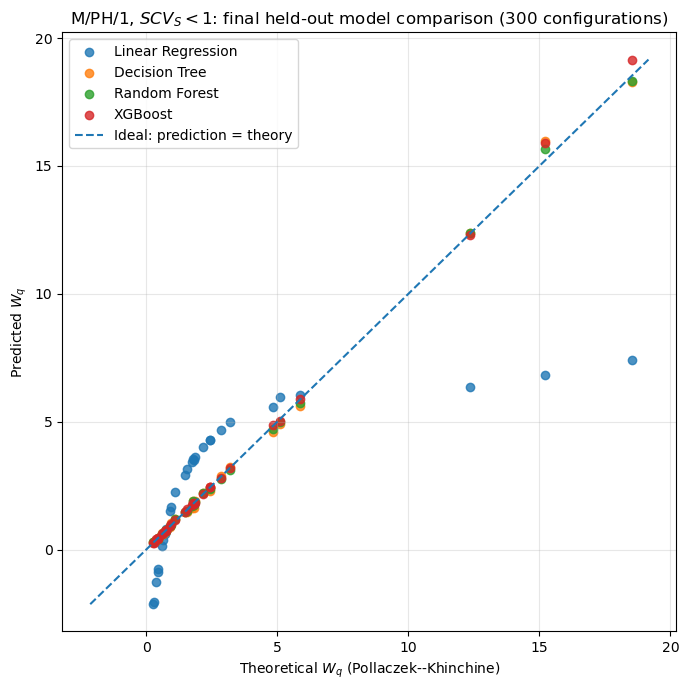

In [26]:
# Predicted versus exact PK Wq.
fig, ax = plt.subplots(figsize=(7, 7))

x = scv_lt1_test_predictions["Wq_theory"]

for model_name, short in short_names.items():
    ax.scatter(
        x,
        scv_lt1_test_predictions[f"Wq_pred_{short}"],
        label=model_name,
        alpha=0.8,
    )

scv_lt1_pred_cols = [
    f"Wq_pred_{short}" for short in short_names.values()
]
lo = min(
    x.min(),
    scv_lt1_test_predictions[scv_lt1_pred_cols].min().min(),
)
hi = max(
    x.max(),
    scv_lt1_test_predictions[scv_lt1_pred_cols].max().max(),
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    label="Ideal: prediction = theory",
)
ax.set_xlabel(r"Theoretical $W_q$ (Pollaczek--Khinchine)")
ax.set_ylabel(r"Predicted $W_q$")
ax.set_title(
    r"M/PH/1, $SCV_S<1$: final held-out model comparison "
    "(300 configurations)"
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "mph1_scv_lt1_final_300_predicted_vs_theoretical_Wq.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


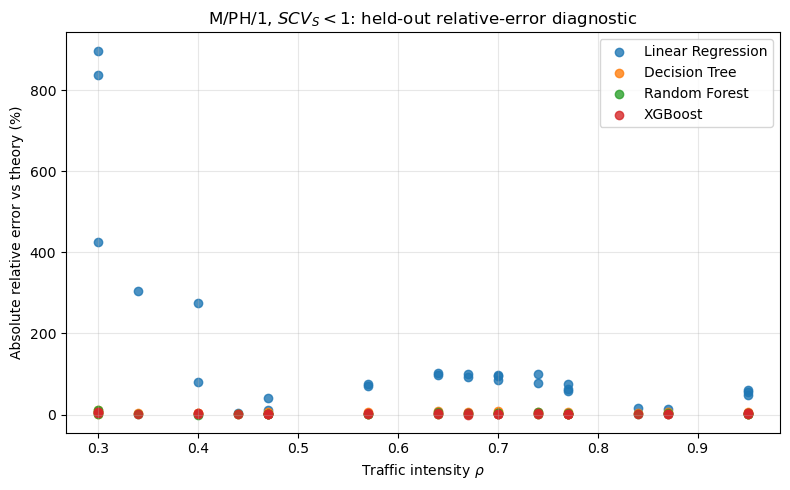

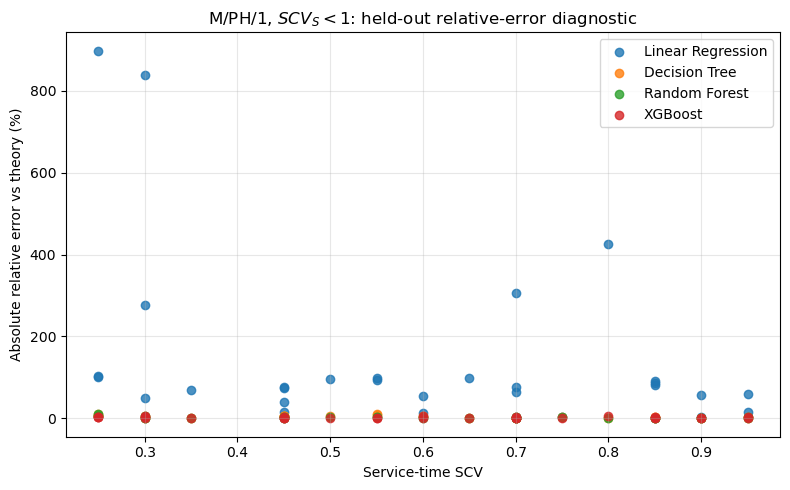

In [27]:
# Primary linear-scale error plots, matching the combined M/PH/1 convention.
scv_lt1_error_cols = {
    model_name: f"Wq_rel_error_pct_{short}_vs_theory"
    for model_name, short in short_names.items()
}

for x_col, x_label, filename in [
    (
        "rho",
        r"Traffic intensity $\rho$",
        "mph1_scv_lt1_final_300_relative_error_vs_rho.png",
    ),
    (
        "service_scv",
        "Service-time SCV",
        "mph1_scv_lt1_final_300_relative_error_vs_scv.png",
    ),
]:
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, error_col in scv_lt1_error_cols.items():
        ax.scatter(
            scv_lt1_test_predictions[x_col],
            scv_lt1_test_predictions[error_col],
            label=model_name,
            alpha=0.8,
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs theory (%)")
    ax.set_title(
        r"M/PH/1, $SCV_S<1$: held-out relative-error diagnostic"
    )
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


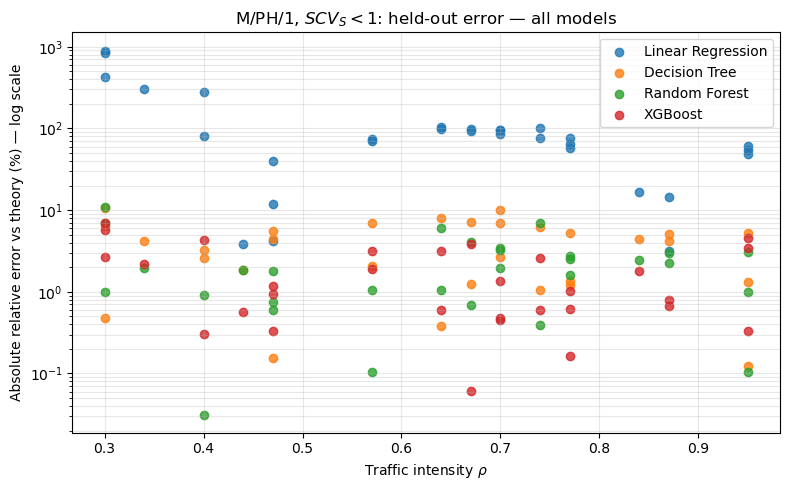

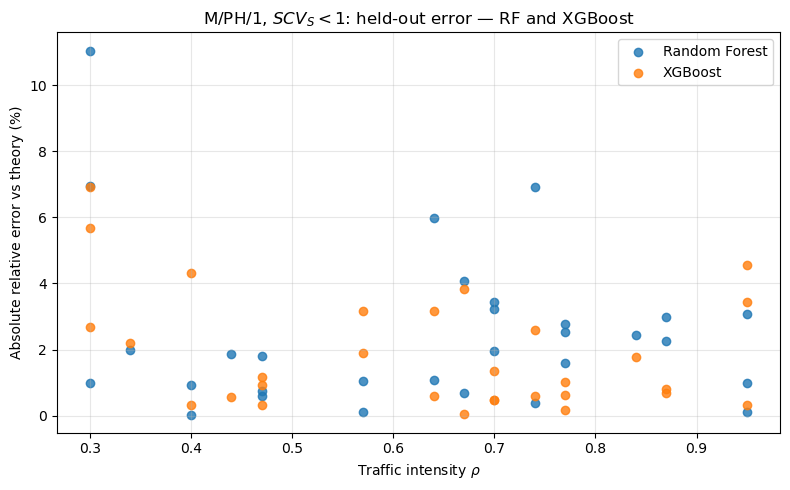

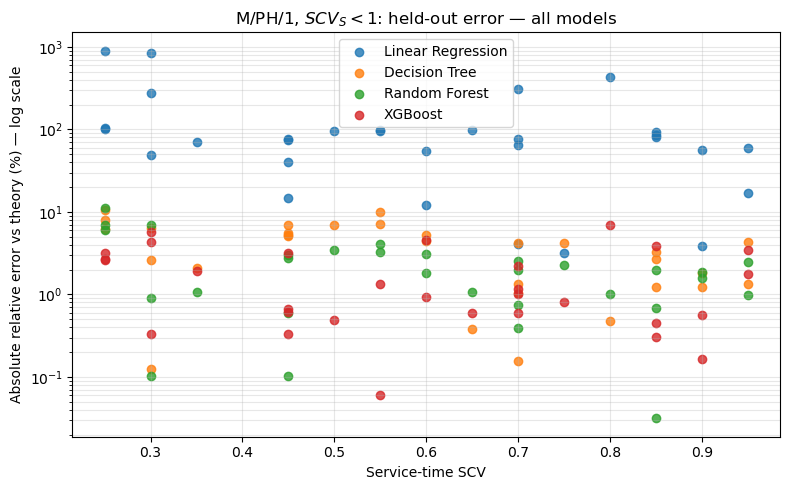

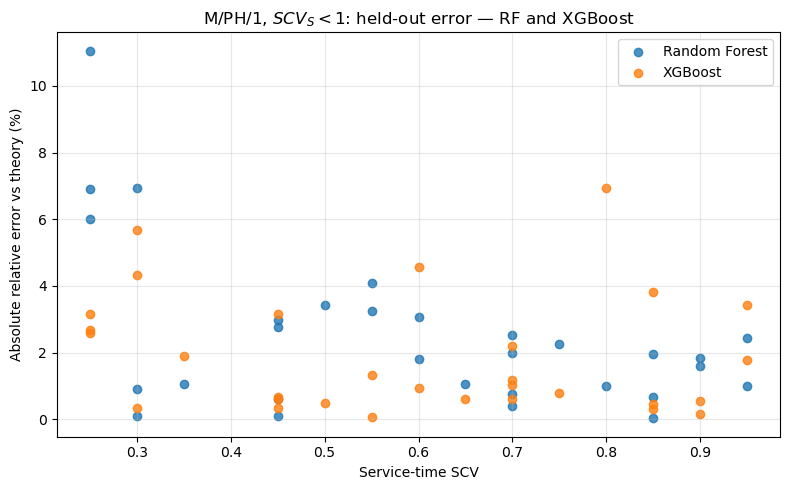

In [28]:
# Supplementary diagnostics.
for x_col, x_label, filename_stem in [
    ("rho", r"Traffic intensity $\rho$", "rho"),
    ("service_scv", "Service-time SCV", "scv"),
]:
    # A. All models on log y-axis.
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, error_col in scv_lt1_error_cols.items():
        y = np.clip(
            scv_lt1_test_predictions[error_col].to_numpy(dtype=float),
            1e-3,
            None,
        )
        ax.scatter(
            scv_lt1_test_predictions[x_col],
            y,
            label=model_name,
            alpha=0.8,
        )

    ax.set_yscale("log")
    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs theory (%) — log scale")
    ax.set_title(
        r"M/PH/1, $SCV_S<1$: held-out error — all models"
    )
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR
        / (
            "mph1_scv_lt1_final_300_relative_error_vs_"
            f"{filename_stem}_log.png"
        ),
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    # B. Focused RF/XGBoost linear-scale diagnostic.
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name in ["Random Forest", "XGBoost"]:
        error_col = scv_lt1_error_cols[model_name]
        ax.scatter(
            scv_lt1_test_predictions[x_col],
            scv_lt1_test_predictions[error_col],
            label=model_name,
            alpha=0.8,
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs theory (%)")
    ax.set_title(
        r"M/PH/1, $SCV_S<1$: held-out error — RF and XGBoost"
    )
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR
        / (
            "mph1_scv_lt1_final_300_relative_error_vs_"
            f"{filename_stem}_RF_XGB.png"
        ),
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


### 11.6 \(SCV_S=1\) exponential consistency check

The regime-specific experiments are separated into \(SCV_S<1\) and \(SCV_S>1\).
The boundary case \(SCV_S=1\) is not treated as a third 300-configuration ML
experiment because, with \(E[S]=1\), the PH service distribution reduces to a
one-phase exponential distribution and the queue is exactly M/M/1.

A compact consistency check is therefore sufficient. The same 20 utilisation
values are simulated with \(SCV_S=1\), using 30 independent replications and the
established 10,000 + 40,000 fixed-time protocol. The M/PH/1 PK benchmark must
coincide with the M/M/1 formula
\[
W_q=\frac{\rho}{1-\rho}.
\]
This section checks both the PH construction and the simulated stationary mean.


In [29]:
# ============================================================
# SCV = 1 boundary / consistency design
# ============================================================

SCV_EQ1_RHO_GRID = RHO_GRID_200.copy()

scv_eq1_design = pd.DataFrame({
    "rho": SCV_EQ1_RHO_GRID,
    "service_scv": np.ones(len(SCV_EQ1_RHO_GRID), dtype=float),
})

scv_eq1_design.insert(
    0,
    "config_id",
    [f"eq1_cfg_{i:03d}" for i in range(len(scv_eq1_design))],
)

scv_eq1_design["stream_id"] = np.arange(len(scv_eq1_design), dtype=int)
scv_eq1_design["seed_namespace"] = 10
scv_eq1_design["service_mean"] = SERVICE_MEAN
scv_eq1_design["lambda_rate"] = scv_eq1_design["rho"] / SERVICE_MEAN
scv_eq1_design["warmup_time"] = SIM_WARMUP_TIME
scv_eq1_design["record_time"] = SIM_RECORD_TIME

scv_eq1_ph_profiles = pd.DataFrame([
    ph_profile_record(SERVICE_MEAN, 1.0)
    for _ in range(len(scv_eq1_design))
])
for col in scv_eq1_ph_profiles.columns:
    scv_eq1_design[col] = scv_eq1_ph_profiles[col].to_numpy()

assert scv_eq1_design["service_scv"].eq(1.0).all()
assert scv_eq1_design["ph_family"].eq("exponential").all()
assert scv_eq1_design["ph_phase_count"].eq(1).all()

scv_eq1_theory_rows = [
    mph1_theory(
        rho=float(row.rho),
        service_scv=1.0,
        service_mean=SERVICE_MEAN,
    )
    for row in scv_eq1_design.itertuples(index=False)
]
scv_eq1_theory_df = pd.DataFrame(scv_eq1_theory_rows)

scv_eq1_design["Wq_theory"] = scv_eq1_theory_df["Wq_theory"].to_numpy()
scv_eq1_design["Lq_theory"] = scv_eq1_theory_df["Lq_theory"].to_numpy()

# With E[S]=1, the M/M/1 service rate is mu=1.
scv_eq1_design["Wq_mm1_theory"] = (
    scv_eq1_design["rho"] / (1.0 - scv_eq1_design["rho"])
)

assert np.allclose(
    scv_eq1_design["Wq_theory"],
    scv_eq1_design["Wq_mm1_theory"],
    rtol=1e-12,
    atol=1e-12,
)

scv_eq1_design.to_csv(
    OUTPUT_DIR / "mph1_scv_eq1_consistency_design.csv",
    index=False,
)

display(scv_eq1_design.head())


,config_id,rho,service_scv,stream_id,seed_namespace,service_mean,lambda_rate,warmup_time,record_time,ph_family,ph_phase_count,ph_alpha,ph_T,ph_mean_check,ph_scv_check,Wq_theory,Lq_theory,Wq_mm1_theory
0,eq1_cfg_000,0.30,1.0,0,10,1.0,0.30,10000.0,40000.0,exponential,1,[1.0],[[-1.0]],1.0,1.0,0.428571,0.128571,0.428571
1,eq1_cfg_001,0.34,1.0,1,10,1.0,0.34,10000.0,40000.0,exponential,1,[1.0],[[-1.0]],1.0,1.0,0.515152,0.175152,0.515152
2,eq1_cfg_002,0.37,1.0,2,10,1.0,0.37,10000.0,40000.0,exponential,1,[1.0],[[-1.0]],1.0,1.0,0.587302,0.217302,0.587302
3,eq1_cfg_003,0.40,1.0,3,10,1.0,0.40,10000.0,40000.0,exponential,1,[1.0],[[-1.0]],1.0,1.0,0.666667,0.266667,0.666667
4,eq1_cfg_004,0.44,1.0,4,10,1.0,0.44,10000.0,40000.0,exponential,1,[1.0],[[-1.0]],1.0,1.0,0.785714,0.345714,0.785714


[1/20] eq1_cfg_000 rho=0.30, SCV=1.00
[20/20] eq1_cfg_019 rho=0.95, SCV=1.00
SCV=1 consistency summary:


,n_configurations,mean_relative_error_pct,median_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,20,1.0958,0.6262,95.0,2.3736


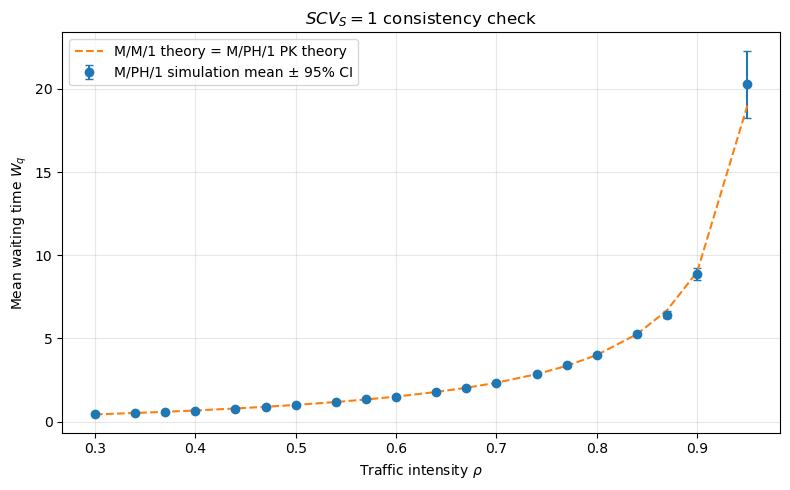

In [30]:
# Run the compact SCV=1 consistency check.
scv_eq1_full_replications, scv_eq1_simulation_runtime_seconds = (
    generate_full_replication_dataset(scv_eq1_design)
)

# Keep this boundary check on its own random-number namespace.
assert set(scv_eq1_full_replications["seed"]).isdisjoint(
    set(check_replications["seed"])
)
assert set(scv_eq1_full_replications["seed"]).isdisjoint(
    set(full_replications["seed"])
)
assert set(scv_eq1_full_replications["seed"]).isdisjoint(
    set(scv_lt1_full_replications["seed"])
)

scv_eq1_labels = aggregate_configuration_labels(
    scv_eq1_full_replications
)
scv_eq1_labels["Wq_mm1_theory"] = (
    scv_eq1_labels["rho"] / (1.0 - scv_eq1_labels["rho"])
)

assert np.allclose(
    scv_eq1_labels["Wq_theory"],
    scv_eq1_labels["Wq_mm1_theory"],
    rtol=1e-12,
    atol=1e-12,
)

scv_eq1_labels["CI_contains_theory"] = (
    (scv_eq1_labels["Wq_ci95_low"] <= scv_eq1_labels["Wq_theory"])
    &
    (scv_eq1_labels["Wq_theory"] <= scv_eq1_labels["Wq_ci95_high"])
)

scv_eq1_summary = pd.DataFrame([{
    "n_configurations": len(scv_eq1_labels),
    "mean_relative_error_pct":
        scv_eq1_labels["Wq_rel_error_vs_theory_pct"].mean(),
    "median_relative_error_pct":
        scv_eq1_labels["Wq_rel_error_vs_theory_pct"].median(),
    "ci95_coverage_pct":
        100.0 * scv_eq1_labels["CI_contains_theory"].mean(),
    "mean_relative_ci_halfwidth_pct":
        scv_eq1_labels["Wq_relative_ci_halfwidth_pct"].mean(),
}])

scv_eq1_full_replications.to_csv(
    OUTPUT_DIR / "mph1_scv_eq1_consistency_replications.csv",
    index=False,
)
scv_eq1_labels.to_csv(
    OUTPUT_DIR / "mph1_scv_eq1_consistency_labels.csv",
    index=False,
)
scv_eq1_summary.to_csv(
    OUTPUT_DIR / "mph1_scv_eq1_consistency_summary.csv",
    index=False,
)

print("SCV=1 consistency summary:")
display(scv_eq1_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 5))

ordered_eq1 = scv_eq1_labels.sort_values("rho")
ax.errorbar(
    ordered_eq1["rho"],
    ordered_eq1["Wq_sim_mean"],
    yerr=ordered_eq1["Wq_ci95_halfwidth"],
    fmt="o",
    capsize=3,
    label="M/PH/1 simulation mean ± 95% CI",
)
ax.plot(
    ordered_eq1["rho"],
    ordered_eq1["Wq_mm1_theory"],
    linestyle="--",
    label="M/M/1 theory = M/PH/1 PK theory",
)

ax.set_xlabel(r"Traffic intensity $\rho$")
ax.set_ylabel(r"Mean waiting time $W_q$")
ax.set_title(r"$SCV_S=1$ consistency check")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "mph1_scv_eq1_consistency_Wq.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 12. Regime-specific M/PH/1 experiment: \(SCV_S > 1\)

This section mirrors the low-SCV experiment using a separate 300-configuration
high-SCV dataset. The PH generator is unchanged. Because every configuration
satisfies \(SCV_S>1\), `build_ph_distribution()` automatically uses the
two-phase hyperexponential (\(H_2\)) construction.

The experimental protocol is kept the same as in Section 11:

- \(E[S]=1\);
- the same 20 utilisation values, \(0.30\leq\rho\leq0.95\);
- 15 SCV levels in the interval \(1.05\leq SCV_S\leq2.00\);
- 30 independent replications per configuration;
- 10,000 warm-up + 40,000 recording time units;
- 300 configurations in total;
- 240 training + 30 validation + 30 held-out test configurations;
- the same LR / DT / RF / XGBoost candidate sets and evaluation metrics.

The purpose is not to re-select the global M/PH/1 methodology, but to obtain a
high-SCV counterpart to the low-SCV experiment for a controlled
regime-specific ML comparison.


### 12.1 Direct 300-configuration high-SCV design


In [31]:
# ============================================================
# SCV > 1 experiment: direct 20 x 15 = 300 configuration grid
# ============================================================

SCV_GT1_RHO_GRID = RHO_GRID_200.copy()
SCV_GT1_GRID = np.round(np.linspace(1.05, 2.00, 15), 4)

scv_gt1_design = (
    pd.MultiIndex.from_product(
        [SCV_GT1_RHO_GRID, SCV_GT1_GRID],
        names=["rho", "service_scv"],
    )
    .to_frame(index=False)
)

scv_gt1_design.insert(
    0,
    "config_id",
    [f"gt1_cfg_{i:03d}" for i in range(len(scv_gt1_design))],
)

assert len(scv_gt1_design) == 300
assert scv_gt1_design["config_id"].is_unique
assert scv_gt1_design["service_scv"].gt(1.0).all()

# Match the low-SCV experiment on rho strata; adapt SCV strata to >1.
scv_gt1_design["rho_band"] = pd.cut(
    scv_gt1_design["rho"],
    bins=[0.299, 0.50, 0.70, 0.85, 0.951],
    labels=["low", "moderate", "high", "very_high"],
    include_lowest=True,
)
scv_gt1_design["scv_band"] = pd.cut(
    scv_gt1_design["service_scv"],
    bins=[1.049, 1.35, 1.70, 2.001],
    labels=["just_above_1", "mid_high_scv", "high_scv"],
    include_lowest=True,
)
scv_gt1_design["stratum"] = (
    scv_gt1_design["rho_band"].astype(str)
    + "_"
    + scv_gt1_design["scv_band"].astype(str)
)

# Separate split draw, with the same 240/30/30 structure as SCV<1.
scv_gt1_train_val, scv_gt1_test = train_test_split(
    scv_gt1_design,
    test_size=N_TEST,
    random_state=BASE_SEED + 2200,
    stratify=scv_gt1_design["stratum"],
)

scv_gt1_train, scv_gt1_validation = train_test_split(
    scv_gt1_train_val,
    test_size=N_VALIDATION,
    random_state=BASE_SEED + 2201,
    stratify=scv_gt1_train_val["stratum"],
)

scv_gt1_design["split"] = ""
scv_gt1_design.loc[
    scv_gt1_design["config_id"].isin(scv_gt1_train["config_id"]), "split"
] = "train"
scv_gt1_design.loc[
    scv_gt1_design["config_id"].isin(scv_gt1_validation["config_id"]),
    "split",
] = "validation"
scv_gt1_design.loc[
    scv_gt1_design["config_id"].isin(scv_gt1_test["config_id"]), "split"
] = "test"

scv_gt1_design["design_batch"] = "scv_gt1_direct_300"

# Independent namespace for this high-SCV experiment.
scv_gt1_design["stream_id"] = np.arange(len(scv_gt1_design), dtype=int)
scv_gt1_design["seed_namespace"] = 12

scv_gt1_design["service_mean"] = SERVICE_MEAN
scv_gt1_design["lambda_rate"] = scv_gt1_design["rho"] / SERVICE_MEAN
scv_gt1_design["warmup_time"] = SIM_WARMUP_TIME
scv_gt1_design["record_time"] = SIM_RECORD_TIME

# Construct and verify the PH representation.
scv_gt1_ph_profiles = pd.DataFrame([
    ph_profile_record(SERVICE_MEAN, float(scv))
    for scv in scv_gt1_design["service_scv"]
])
for col in scv_gt1_ph_profiles.columns:
    scv_gt1_design[col] = scv_gt1_ph_profiles[col].to_numpy()

assert scv_gt1_design["ph_family"].eq("hyperexponential_2").all()
assert scv_gt1_design["ph_phase_count"].eq(2).all()

# Exact PK benchmark.
scv_gt1_theory_rows = [
    mph1_theory(
        rho=float(row.rho),
        service_scv=float(row.service_scv),
        service_mean=SERVICE_MEAN,
    )
    for row in scv_gt1_design.itertuples(index=False)
]
scv_gt1_theory_df = pd.DataFrame(scv_gt1_theory_rows)
scv_gt1_design["Wq_theory"] = scv_gt1_theory_df["Wq_theory"].to_numpy()
scv_gt1_design["Lq_theory"] = scv_gt1_theory_df["Lq_theory"].to_numpy()

scv_gt1_split_counts = scv_gt1_design["split"].value_counts()
assert scv_gt1_split_counts["train"] == N_TRAIN
assert scv_gt1_split_counts["validation"] == N_VALIDATION
assert scv_gt1_split_counts["test"] == N_TEST

scv_gt1_design.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_configuration_design_300.csv",
    index=False,
)

scv_gt1_coverage = pd.crosstab(
    [scv_gt1_design["rho_band"], scv_gt1_design["scv_band"]],
    scv_gt1_design["split"],
    dropna=False,
)
scv_gt1_coverage.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_configuration_split_coverage.csv"
)

print("SCV>1 split counts:")
print(scv_gt1_split_counts)
print(
    "\nSCV range:",
    scv_gt1_design["service_scv"].min(),
    "to",
    scv_gt1_design["service_scv"].max(),
)
print("PH families:", scv_gt1_design["ph_family"].value_counts().to_dict())
display(scv_gt1_coverage)
display(scv_gt1_design.head(12))


SCV>1 split counts:
split
train         240
test           30
validation     30
Name: count, dtype: int64

SCV range: 1.05 to 2.0
PH families: {'hyperexponential_2': 300}


split                   test  train  validation
rho_band  scv_band                             
low       just_above_1     3     28           4
          mid_high_scv     3     28           4
          high_scv         4     28           3
moderate  just_above_1     3     24           3
          mid_high_scv     3     24           3
          high_scv         3     24           3
high      just_above_1     2     16           2
          mid_high_scv     2     16           2
          high_scv         2     16           2
very_high just_above_1     1     12           2
          mid_high_scv     2     12           1
          high_scv         2     12           1

,config_id,rho,service_scv,rho_band,scv_band,stratum,split,design_batch,stream_id,seed_namespace,...,warmup_time,record_time,ph_family,ph_phase_count,ph_alpha,ph_T,ph_mean_check,ph_scv_check,Wq_theory,Lq_theory
0,gt1_cfg_000,0.3,1.0500,low,just_above_1,low_just_above_1,train,scv_gt1_direct_300,0,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.578086880944303, 0.42191311905569695]","[[-1.156173761888606, 0.0], [0.0, -0.843826238...",1.0,1.0500,0.439286,0.131786
1,gt1_cfg_001,0.3,1.1179,low,just_above_1,low_just_above_1,train,scv_gt1_direct_300,1,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.6179707068775704, 0.3820292931224296]","[[-1.2359414137551408, 0.0], [0.0, -0.76405858...",1.0,1.1179,0.453836,0.136151
2,gt1_cfg_002,0.3,1.1857,low,just_above_1,low_just_above_1,test,scv_gt1_direct_300,2,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.6457406425955015, 0.35425935740449854]","[[-1.291481285191003, 0.0], [0.0, -0.708518714...",1.0,1.1857,0.468364,0.140509
3,gt1_cfg_003,0.3,1.2536,low,just_above_1,low_just_above_1,train,scv_gt1_direct_300,3,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.6677282485248464, 0.33227175147515364]","[[-1.3354564970496927, 0.0], [0.0, -0.66454350...",1.0,1.2536,0.482914,0.144874
4,gt1_cfg_004,0.3,1.3214,low,just_above_1,low_just_above_1,train,scv_gt1_direct_300,4,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.6860449776134361, 0.3139550223865639]","[[-1.3720899552268722, 0.0], [0.0, -0.62791004...",1.0,1.3214,0.497443,0.149233
5,gt1_cfg_005,0.3,1.3893,low,mid_high_scv,low_mid_high_scv,train,scv_gt1_direct_300,5,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.7018258845910392, 0.29817411540896077]","[[-1.4036517691820785, 0.0], [0.0, -0.59634823...",1.0,1.3893,0.511993,0.153598
6,gt1_cfg_006,0.3,1.4571,low,mid_high_scv,low_mid_high_scv,train,scv_gt1_direct_300,6,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.7156573175880624, 0.2843426824119376]","[[-1.4313146351761248, 0.0], [0.0, -0.56868536...",1.0,1.4571,0.526521,0.157956
7,gt1_cfg_007,0.3,1.5250,low,mid_high_scv,low_mid_high_scv,train,scv_gt1_direct_300,7,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.7279916621716723, 0.2720083378283277]","[[-1.4559833243433447, 0.0], [0.0, -0.54401667...",1.0,1.5250,0.541071,0.162321
8,gt1_cfg_008,0.3,1.5929,low,mid_high_scv,low_mid_high_scv,train,scv_gt1_direct_300,8,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.7390935419008706, 0.2609064580991294]","[[-1.4781870838017412, 0.0], [0.0, -0.52181291...",1.0,1.5929,0.555621,0.166686
9,gt1_cfg_009,0.3,1.6607,low,mid_high_scv,low_mid_high_scv,train,scv_gt1_direct_300,9,12,...,10000.0,40000.0,hyperexponential_2,2,"[0.7491576367358107, 0.2508423632641893]","[[-1.4983152734716214, 0.0], [0.0, -0.50168472...",1.0,1.6607,0.570150,0.171045


### 12.2 Generate stationary labels and validate the high-SCV simulator


In [32]:
# Reuse the established simulation helper; do not redefine it.
scv_gt1_full_replications, scv_gt1_simulation_runtime_seconds = (
    generate_full_replication_dataset(scv_gt1_design)
)

# High-SCV random streams must be disjoint from every earlier experiment.
for prior_seed_set in [
    set(check_replications["seed"]),
    set(full_replications["seed"]),
    set(scv_lt1_full_replications["seed"]),
    set(scv_eq1_full_replications["seed"]),
]:
    assert set(scv_gt1_full_replications["seed"]).isdisjoint(prior_seed_set)

scv_gt1_full_replications.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_full_300_replications.csv",
    index=False,
)

scv_gt1_stationary_labels = aggregate_configuration_labels(
    scv_gt1_full_replications
)
scv_gt1_stationary_labels = scv_gt1_stationary_labels.merge(
    scv_gt1_design[
        [
            "config_id", "split", "rho_band", "scv_band",
            "design_batch", "stream_id", "seed_namespace",
        ]
    ],
    on="config_id",
    how="left",
    validate="one_to_one",
)

assert len(scv_gt1_stationary_labels) == 300
assert scv_gt1_stationary_labels["config_id"].is_unique
assert scv_gt1_stationary_labels["service_scv"].gt(1.0).all()
assert scv_gt1_stationary_labels["ph_family"].eq("hyperexponential_2").all()

scv_gt1_stationary_labels["CI_contains_theory"] = (
    (scv_gt1_stationary_labels["Wq_ci95_low"]
     <= scv_gt1_stationary_labels["Wq_theory"])
    &
    (scv_gt1_stationary_labels["Wq_theory"]
     <= scv_gt1_stationary_labels["Wq_ci95_high"])
)

scv_gt1_stationary_labels.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_stationary_300_labels.csv",
    index=False,
)

print(
    "SCV>1 full 300-configuration label generation completed in "
    f"{scv_gt1_simulation_runtime_seconds/60:.2f} minutes."
)
display(scv_gt1_stationary_labels.head())


[1/300] gt1_cfg_000 rho=0.30, SCV=1.05
[25/300] gt1_cfg_024 rho=0.34, SCV=1.66
[50/300] gt1_cfg_049 rho=0.40, SCV=1.32
[75/300] gt1_cfg_074 rho=0.44, SCV=2.00
[100/300] gt1_cfg_099 rho=0.50, SCV=1.66
[125/300] gt1_cfg_124 rho=0.57, SCV=1.32
[150/300] gt1_cfg_149 rho=0.60, SCV=2.00
[175/300] gt1_cfg_174 rho=0.67, SCV=1.66
[200/300] gt1_cfg_199 rho=0.74, SCV=1.32
[225/300] gt1_cfg_224 rho=0.77, SCV=2.00
[250/300] gt1_cfg_249 rho=0.84, SCV=1.66
[275/300] gt1_cfg_274 rho=0.90, SCV=1.32
[300/300] gt1_cfg_299 rho=0.95, SCV=2.00
SCV>1 full 300-configuration label generation completed in 0.17 minutes.


,config_id,rho,lambda_rate,service_mean,service_scv,ph_family,ph_phase_count,warmup_time,record_time,n_replications,...,service_mean_hat_mean,service_scv_hat_mean,mean_runtime_seconds_per_rep,split,rho_band,scv_band,design_batch,stream_id,seed_namespace,CI_contains_theory
0,gt1_cfg_000,0.3,0.3,1.0,1.0500,hyperexponential_2,2,10000.0,40000.0,30,...,1.002466,1.050245,0.000661,train,low,just_above_1,scv_gt1_direct_300,0,12,True
1,gt1_cfg_001,0.3,0.3,1.0,1.1179,hyperexponential_2,2,10000.0,40000.0,30,...,1.002719,1.117316,0.000619,train,low,just_above_1,scv_gt1_direct_300,1,12,False
2,gt1_cfg_002,0.3,0.3,1.0,1.1857,hyperexponential_2,2,10000.0,40000.0,30,...,0.997879,1.182346,0.000647,test,low,just_above_1,scv_gt1_direct_300,2,12,False
3,gt1_cfg_003,0.3,0.3,1.0,1.2536,hyperexponential_2,2,10000.0,40000.0,30,...,1.001795,1.249254,0.000663,train,low,just_above_1,scv_gt1_direct_300,3,12,True
4,gt1_cfg_004,0.3,0.3,1.0,1.3214,hyperexponential_2,2,10000.0,40000.0,30,...,0.999669,1.313347,0.000664,train,low,just_above_1,scv_gt1_direct_300,4,12,False


In [33]:
# ============================================================
# Empirical input-process validation
# ============================================================

scv_gt1_stationary_labels["lambda_rel_error_pct"] = (
    100.0
    * (
        scv_gt1_stationary_labels["lambda_hat_mean"]
        - scv_gt1_stationary_labels["lambda_rate"]
    ).abs()
    / scv_gt1_stationary_labels["lambda_rate"].abs()
)
scv_gt1_stationary_labels["service_mean_rel_error_pct"] = (
    100.0
    * (
        scv_gt1_stationary_labels["service_mean_hat_mean"]
        - scv_gt1_stationary_labels["service_mean"]
    ).abs()
    / scv_gt1_stationary_labels["service_mean"].abs()
)
scv_gt1_stationary_labels["service_scv_rel_error_pct"] = (
    100.0
    * (
        scv_gt1_stationary_labels["service_scv_hat_mean"]
        - scv_gt1_stationary_labels["service_scv"]
    ).abs()
    / scv_gt1_stationary_labels["service_scv"].abs()
)

scv_gt1_input_validation = pd.DataFrame([{
    "n_configurations": len(scv_gt1_stationary_labels),
    "mean_lambda_rel_error_pct":
        scv_gt1_stationary_labels["lambda_rel_error_pct"].mean(),
    "max_lambda_rel_error_pct":
        scv_gt1_stationary_labels["lambda_rel_error_pct"].max(),
    "mean_service_mean_rel_error_pct":
        scv_gt1_stationary_labels["service_mean_rel_error_pct"].mean(),
    "max_service_mean_rel_error_pct":
        scv_gt1_stationary_labels["service_mean_rel_error_pct"].max(),
    "mean_service_scv_rel_error_pct":
        scv_gt1_stationary_labels["service_scv_rel_error_pct"].mean(),
    "max_service_scv_rel_error_pct":
        scv_gt1_stationary_labels["service_scv_rel_error_pct"].max(),
}])

scv_gt1_input_validation.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_input_process_validation_300.csv",
    index=False,
)

# ============================================================
# Stationary simulation quality
# ============================================================

scv_gt1_quality_overall = quality_summary(
    scv_gt1_stationary_labels
).to_frame().T

scv_gt1_quality_by_rho = (
    scv_gt1_stationary_labels
    .groupby("rho_band", observed=True)
    .apply(quality_summary, include_groups=False)
    .reset_index()
)

scv_gt1_quality_by_scv = (
    scv_gt1_stationary_labels
    .groupby("scv_band", observed=True)
    .apply(quality_summary, include_groups=False)
    .reset_index()
)

scv_gt1_quality_overall.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_simulation_quality_300.csv",
    index=False,
)
scv_gt1_quality_by_rho.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_simulation_quality_by_rho_band.csv",
    index=False,
)
scv_gt1_quality_by_scv.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_simulation_quality_by_scv_band.csv",
    index=False,
)

print("SCV>1 empirical input-process validation:")
display(scv_gt1_input_validation.round(4))
print("SCV>1 overall simulation quality:")
display(scv_gt1_quality_overall.round(4))
print("SCV>1 simulation quality by rho band:")
display(scv_gt1_quality_by_rho.round(4))
print("SCV>1 simulation quality by SCV band:")
display(scv_gt1_quality_by_scv.round(4))


SCV>1 empirical input-process validation:


,n_configurations,mean_lambda_rel_error_pct,max_lambda_rel_error_pct,mean_service_mean_rel_error_pct,max_service_mean_rel_error_pct,mean_service_scv_rel_error_pct,max_service_scv_rel_error_pct
0,300,0.0971,0.3182,0.1101,0.4541,0.2825,1.3059


SCV>1 overall simulation quality:


,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,300.0,1.0131,0.7326,2.1843,93.3333,2.527


SCV>1 simulation quality by rho band:


,rho_band,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,low,105.0,0.7695,0.6460,1.5659,91.4286,1.7362
1,moderate,90.0,0.7438,0.6449,1.4123,94.4444,1.8407
2,high,60.0,1.0519,0.8365,2.1925,91.6667,2.5070
3,very_high,45.0,2.0682,1.4148,4.8296,97.7778,5.7715


SCV>1 simulation quality by SCV band:


,scv_band,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,just_above_1,100.0,0.8319,0.5995,1.6394,94.0,2.2462
1,mid_high_scv,100.0,0.9006,0.6736,1.7506,97.0,2.5530
2,high_scv,100.0,1.3067,0.9780,2.4098,89.0,2.7819


### 12.3 ML experiment

The prediction problem is
\[
(\rho,SCV_S)\rightarrow W_q,
\qquad SCV_S>1.
\]
The same four models and candidate hyperparameter grids are reused. Model
selection uses only the 30 high-SCV validation configurations.


In [34]:
SCV_GT1_FEATURE_COLS = ["rho", "service_scv"]
SCV_GT1_TARGET_COL = "Wq_sim_mean"

scv_gt1_train_df = scv_gt1_stationary_labels[
    scv_gt1_stationary_labels["split"] == "train"
].copy()
scv_gt1_val_df = scv_gt1_stationary_labels[
    scv_gt1_stationary_labels["split"] == "validation"
].copy()
scv_gt1_test_df = scv_gt1_stationary_labels[
    scv_gt1_stationary_labels["split"] == "test"
].copy()

assert len(scv_gt1_train_df) == N_TRAIN
assert len(scv_gt1_val_df) == N_VALIDATION
assert len(scv_gt1_test_df) == N_TEST

scv_gt1_X_train = scv_gt1_train_df[SCV_GT1_FEATURE_COLS]
scv_gt1_y_train = scv_gt1_train_df[SCV_GT1_TARGET_COL]
scv_gt1_X_val = scv_gt1_val_df[SCV_GT1_FEATURE_COLS]
scv_gt1_y_val = scv_gt1_val_df[SCV_GT1_TARGET_COL].to_numpy()
scv_gt1_X_test = scv_gt1_test_df[SCV_GT1_FEATURE_COLS]


def select_on_validation_scv_gt1(model_name, candidates):
    rows = []

    for params in candidates:
        model = fit_candidate(model_name, params)
        start = time.perf_counter()
        model.fit(scv_gt1_X_train, scv_gt1_y_train)
        train_seconds = time.perf_counter() - start
        pred = model.predict(scv_gt1_X_val)

        rows.append({
            **params,
            "validation_RMSE_vs_sim_label": rmse(scv_gt1_y_val, pred),
            "training_seconds": train_seconds,
        })

    search = (
        pd.DataFrame(rows)
        .sort_values("validation_RMSE_vs_sim_label")
        .reset_index(drop=True)
    )
    return search.iloc[0].to_dict(), search


scv_gt1_lr_val = LinearRegression()
scv_gt1_lr_val.fit(scv_gt1_X_train, scv_gt1_y_train)
scv_gt1_lr_val_pred = scv_gt1_lr_val.predict(scv_gt1_X_val)

scv_gt1_selected_settings = {"Linear Regression": {}}
scv_gt1_search_tables = {}

for model_name, candidates in [
    ("Decision Tree", dt_candidates),
    ("Random Forest", rf_candidates),
    ("XGBoost", xgb_candidates),
]:
    best, search = select_on_validation_scv_gt1(model_name, candidates)
    scv_gt1_selected_settings[model_name] = best
    scv_gt1_search_tables[model_name] = search

    model_slug = model_name.lower().replace(" ", "_")
    search.to_csv(
        OUTPUT_DIR
        / f"mph1_scv_gt1_{model_slug}_validation_search.csv",
        index=False,
    )

scv_gt1_selected_settings_table = pd.DataFrame([
    {
        "Model": model_name,
        "selected_settings": (
            "raw rho + SCV; no tuning"
            if model_name == "Linear Regression"
            else json.dumps(
                {
                    k: json_safe_setting(k, v)
                    for k, v in settings.items()
                    if k not in {
                        "validation_RMSE_vs_sim_label",
                        "training_seconds",
                    }
                },
                allow_nan=False,
            )
        ),
    }
    for model_name, settings in scv_gt1_selected_settings.items()
])

scv_gt1_selected_settings_table.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_selected_settings_300.csv",
    index=False,
)

print(
    "SCV>1 Linear Regression validation RMSE:",
    round(rmse(scv_gt1_y_val, scv_gt1_lr_val_pred), 6),
)
display(scv_gt1_selected_settings_table)

for model_name, search in scv_gt1_search_tables.items():
    print(f"\nSCV>1 {model_name} validation search:")
    display(search.round(6))


SCV>1 Linear Regression validation RMSE: 3.145079


,Model,selected_settings
0,Linear Regression,raw rho + SCV; no tuning
1,Decision Tree,"{""max_depth"": null, ""min_samples_leaf"": 2}"
2,Random Forest,"{""n_estimators"": 300, ""max_depth"": null, ""min_..."
3,XGBoost,"{""n_estimators"": 150, ""max_depth"": 2, ""learnin..."



SCV>1 Decision Tree validation search:


,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,NaN,2,0.506572,0.000365
1,5.0,2,0.571971,0.000496
2,4.0,1,0.710162,0.000506
3,4.0,2,0.710162,0.000419
4,3.0,1,0.745226,0.000472
5,3.0,2,0.745226,0.000475
6,5.0,1,0.790113,0.000439
7,2.0,1,1.153083,0.000641



SCV>1 Random Forest validation search:


,n_estimators,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,300,NaN,2,0.400740,0.096798
1,300,5.0,2,0.439076,0.096005
2,300,NaN,1,0.561861,0.095909
3,300,5.0,1,0.607834,0.098571
4,300,3.0,2,0.670100,0.099128
5,300,3.0,1,0.720327,0.100657



SCV>1 XGBoost validation search:


,n_estimators,max_depth,learning_rate,validation_RMSE_vs_sim_label,training_seconds
0,150,2,0.03,0.373225,0.017657
1,150,3,0.03,0.385127,0.017285
2,150,2,0.05,0.455232,0.012999
3,250,2,0.03,0.464996,0.020756
4,250,2,0.05,0.483883,0.030533
5,250,3,0.03,0.596408,0.030561
6,150,3,0.05,0.598546,0.016606
7,250,3,0.05,0.622721,0.028606


### 12.4 Final held-out evaluation


In [35]:
scv_gt1_development_df = pd.concat(
    [scv_gt1_train_df, scv_gt1_val_df],
    ignore_index=True,
)

scv_gt1_X_dev = scv_gt1_development_df[SCV_GT1_FEATURE_COLS]
scv_gt1_y_dev = scv_gt1_development_df[SCV_GT1_TARGET_COL]
scv_gt1_y_test_sim = scv_gt1_test_df[SCV_GT1_TARGET_COL].to_numpy()
scv_gt1_y_test_theory = scv_gt1_test_df["Wq_theory"].to_numpy()

assert len(scv_gt1_development_df) == N_TRAIN + N_VALIDATION
assert set(scv_gt1_development_df["config_id"]).isdisjoint(
    set(scv_gt1_test_df["config_id"])
)

scv_gt1_final_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": fit_candidate(
        "Decision Tree",
        clean_selected_params(
            "Decision Tree",
            scv_gt1_selected_settings["Decision Tree"],
        ),
    ),
    "Random Forest": fit_candidate(
        "Random Forest",
        clean_selected_params(
            "Random Forest",
            scv_gt1_selected_settings["Random Forest"],
        ),
    ),
    "XGBoost": fit_candidate(
        "XGBoost",
        clean_selected_params(
            "XGBoost",
            scv_gt1_selected_settings["XGBoost"],
        ),
    ),
}

scv_gt1_final_predictions = {}
scv_gt1_training_times = {}
scv_gt1_prediction_times = {}

for model_name, model in scv_gt1_final_models.items():
    start = time.perf_counter()
    model.fit(scv_gt1_X_dev, scv_gt1_y_dev)
    scv_gt1_training_times[model_name] = time.perf_counter() - start

    scv_gt1_final_predictions[model_name] = model.predict(scv_gt1_X_test)
    scv_gt1_prediction_times[model_name] = average_prediction_time(
        model,
        scv_gt1_X_test,
        repeats=50,
    )

scv_gt1_metric_rows = []
for model_name, pred in scv_gt1_final_predictions.items():
    scv_gt1_metric_rows.append({
        "Model": model_name,
        "Reference": "simulation mean label",
        **regression_metrics(scv_gt1_y_test_sim, pred),
    })
    scv_gt1_metric_rows.append({
        "Model": model_name,
        "Reference": "PK theory",
        **regression_metrics(scv_gt1_y_test_theory, pred),
    })

scv_gt1_final_test_metrics = pd.DataFrame(scv_gt1_metric_rows)
scv_gt1_final_test_metrics.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_final_300_test_metrics.csv",
    index=False,
)

scv_gt1_timing = pd.DataFrame([
    {
        "Model": model_name,
        "training_seconds": scv_gt1_training_times[model_name],
        "prediction_seconds_for_30_test_configs":
            scv_gt1_prediction_times[model_name],
    }
    for model_name in scv_gt1_final_models
])
scv_gt1_timing.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_final_300_timing.csv",
    index=False,
)

print("SCV>1 final held-out test metrics:")
display(scv_gt1_final_test_metrics.round(6))
print("SCV>1 final model timing:")
display(scv_gt1_timing.round(6))


SCV>1 final held-out test metrics:


,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,simulation mean label,2.841607,4.865643,0.535489,96.192972,56.106419
1,Linear Regression,PK theory,2.778091,4.678090,0.550201,95.522158,57.076933
2,Decision Tree,simulation mean label,0.294066,0.618395,0.992497,4.263021,4.153272
3,Decision Tree,PK theory,0.134962,0.199690,0.999180,3.505044,3.585894
4,Random Forest,simulation mean label,0.280802,0.658408,0.991494,3.826368,3.144487
5,Random Forest,PK theory,0.144270,0.241885,0.998797,2.999870,2.627288
6,XGBoost,simulation mean label,0.368900,0.761896,0.988610,10.020366,8.249929
7,XGBoost,PK theory,0.259232,0.425489,0.996279,9.203845,7.040831


SCV>1 final model timing:


,Model,training_seconds,prediction_seconds_for_30_test_configs
0,Linear Regression,0.000564,0.000144
1,Decision Tree,0.000901,0.000163
2,Random Forest,0.112861,0.013570
3,XGBoost,0.014122,0.000172


In [36]:
scv_gt1_test_predictions = scv_gt1_test_df[
    [
        "config_id",
        "rho",
        "lambda_rate",
        "service_scv",
        "ph_family",
        "ph_phase_count",
        "Wq_sim_mean",
        "Wq_theory",
        "Wq_ci95_low",
        "Wq_ci95_high",
        "Wq_relative_ci_halfwidth_pct",
        "Lq_theory",
        "Lq_derived_from_Wq",
    ]
].copy()

for model_name, pred in scv_gt1_final_predictions.items():
    short = short_names[model_name]

    scv_gt1_test_predictions[f"Wq_pred_{short}"] = pred
    scv_gt1_test_predictions[f"Lq_derived_pred_{short}"] = (
        scv_gt1_test_predictions["lambda_rate"] * pred
    )
    scv_gt1_test_predictions[f"Wq_abs_error_{short}_vs_theory"] = (
        scv_gt1_test_predictions[f"Wq_pred_{short}"]
        - scv_gt1_test_predictions["Wq_theory"]
    ).abs()
    scv_gt1_test_predictions[f"Wq_rel_error_pct_{short}_vs_theory"] = (
        100.0
        * scv_gt1_test_predictions[f"Wq_abs_error_{short}_vs_theory"]
        / scv_gt1_test_predictions["Wq_theory"].abs()
    )

scv_gt1_test_predictions.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_final_300_test_predictions.csv",
    index=False,
)

scv_gt1_lq_metric_rows = []
for model_name, short in short_names.items():
    scv_gt1_lq_metric_rows.append({
        "Model": model_name,
        "Construction": "derived from Wq prediction via Little's Law",
        **regression_metrics(
            scv_gt1_test_predictions["Lq_theory"].to_numpy(),
            scv_gt1_test_predictions[
                f"Lq_derived_pred_{short}"
            ].to_numpy(),
        ),
    })

scv_gt1_derived_lq_metrics = pd.DataFrame(
    scv_gt1_lq_metric_rows
)
scv_gt1_derived_lq_metrics.to_csv(
    OUTPUT_DIR / "mph1_scv_gt1_derived_Lq_test_metrics.csv",
    index=False,
)

display(scv_gt1_test_predictions.head())
display(scv_gt1_derived_lq_metrics.round(6))


,config_id,rho,lambda_rate,service_scv,ph_family,ph_phase_count,Wq_sim_mean,Wq_theory,Wq_ci95_low,Wq_ci95_high,...,Wq_abs_error_DT_vs_theory,Wq_rel_error_pct_DT_vs_theory,Wq_pred_RF,Lq_derived_pred_RF,Wq_abs_error_RF_vs_theory,Wq_rel_error_pct_RF_vs_theory,Wq_pred_XGB,Lq_derived_pred_XGB,Wq_abs_error_XGB_vs_theory,Wq_rel_error_pct_XGB_vs_theory
2,gt1_cfg_002,0.30,0.30,1.1857,hyperexponential_2,2,0.460134,0.468364,0.452703,0.467565,...,0.015998,3.415774,0.476248,0.142874,0.007884,1.683219,0.714364,0.214309,0.246000,52.523233
19,gt1_cfg_019,0.34,0.34,1.3214,hyperexponential_2,2,0.601037,0.597936,0.592644,0.609430,...,0.022945,3.837406,0.595271,0.202392,0.002665,0.445725,0.767497,0.260949,0.169560,28.357580
36,gt1_cfg_036,0.37,0.37,1.4571,hyperexponential_2,2,0.721581,0.721529,0.708274,0.734889,...,0.026940,3.733724,0.724049,0.267898,0.002520,0.349200,0.831237,0.307558,0.109707,15.204844
57,gt1_cfg_057,0.40,0.40,1.8643,hyperexponential_2,2,0.961273,0.954767,0.941734,0.980812,...,0.021432,2.244723,0.953247,0.381299,0.001520,0.159184,1.135135,0.454054,0.180368,18.891345
67,gt1_cfg_067,0.44,0.44,1.5250,hyperexponential_2,2,0.988767,0.991964,0.972616,1.004919,...,0.043255,4.360583,0.988325,0.434863,0.003639,0.366889,1.103891,0.485712,0.111926,11.283319


,Model,Construction,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,derived from Wq prediction via Little's Law,2.198270,4.289289,0.598383,95.522158,57.076933
1,Decision Tree,derived from Wq prediction via Little's Law,0.107934,0.173837,0.999340,3.505044,3.585894
2,Random Forest,derived from Wq prediction via Little's Law,0.120030,0.218055,0.998962,2.999870,2.627288
3,XGBoost,derived from Wq prediction via Little's Law,0.201810,0.381487,0.996823,9.203845,7.040831


### 12.5 SCV>1 diagnostic plots


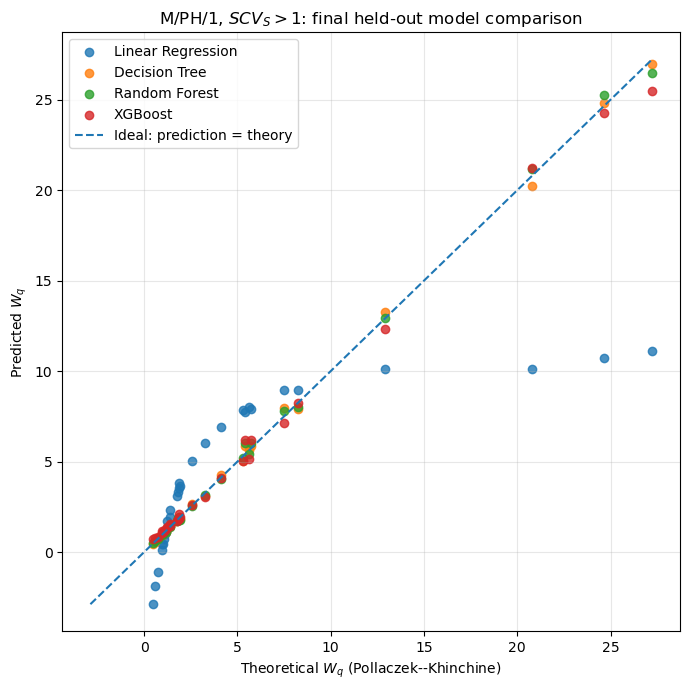

In [37]:
# Predicted versus exact PK Wq.
fig, ax = plt.subplots(figsize=(7, 7))

x = scv_gt1_test_predictions["Wq_theory"]

for model_name, short in short_names.items():
    ax.scatter(
        x,
        scv_gt1_test_predictions[f"Wq_pred_{short}"],
        label=model_name,
        alpha=0.8,
    )

scv_gt1_pred_cols = [
    f"Wq_pred_{short}" for short in short_names.values()
]
lo = min(
    x.min(),
    scv_gt1_test_predictions[scv_gt1_pred_cols].min().min(),
)
hi = max(
    x.max(),
    scv_gt1_test_predictions[scv_gt1_pred_cols].max().max(),
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    label="Ideal: prediction = theory",
)
ax.set_xlabel(r"Theoretical $W_q$ (Pollaczek--Khinchine)")
ax.set_ylabel(r"Predicted $W_q$")
ax.set_title(
    r"M/PH/1, $SCV_S>1$: final held-out model comparison"
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR
    / "mph1_scv_gt1_final_300_predicted_vs_theoretical_Wq.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


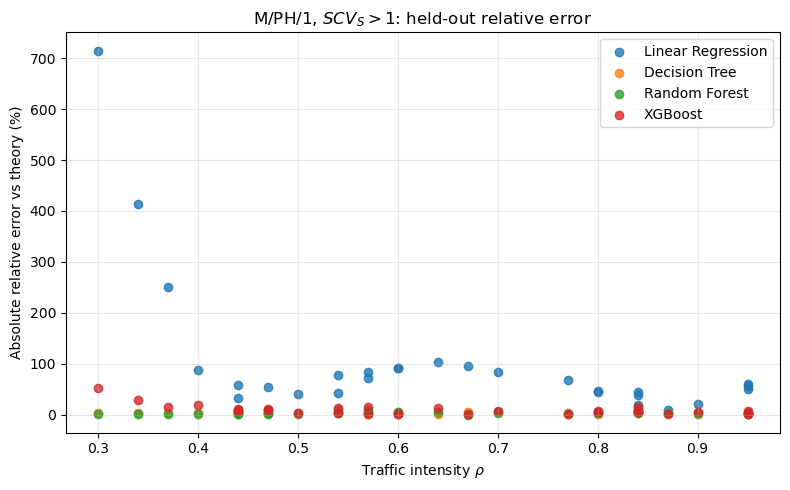

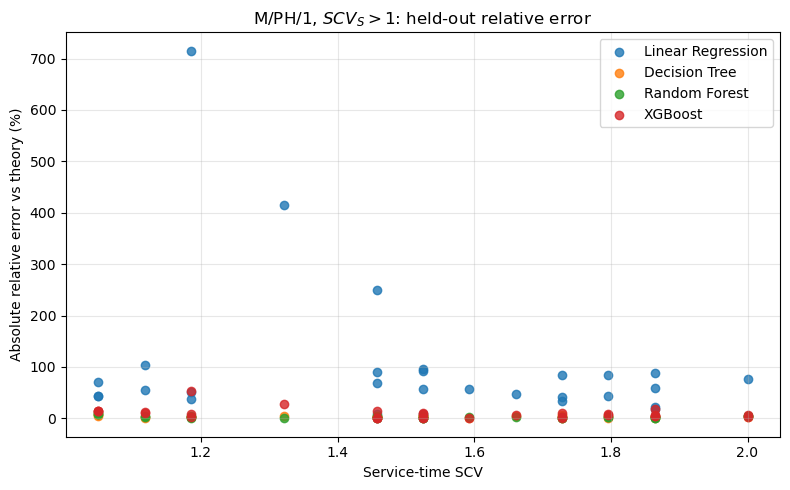

In [38]:
# Primary linear-scale error plots, matching SCV<1 and combined M/PH/1.
scv_gt1_error_cols = {
    model_name: f"Wq_rel_error_pct_{short}_vs_theory"
    for model_name, short in short_names.items()
}

for x_col, x_label, filename in [
    (
        "rho",
        r"Traffic intensity $\rho$",
        "mph1_scv_gt1_final_300_relative_error_vs_rho.png",
    ),
    (
        "service_scv",
        "Service-time SCV",
        "mph1_scv_gt1_final_300_relative_error_vs_scv.png",
    ),
]:
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, error_col in scv_gt1_error_cols.items():
        ax.scatter(
            scv_gt1_test_predictions[x_col],
            scv_gt1_test_predictions[error_col],
            label=model_name,
            alpha=0.8,
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs theory (%)")
    ax.set_title(
        r"M/PH/1, $SCV_S>1$: held-out relative error"
    )
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


## 13. Low-SCV vs High-SCV ML comparison

This section compares the two regime-specific experiments:

- \(SCV_S<1\): generalized-Erlang / sequential hypoexponential PH service;
- \(SCV_S>1\): two-phase hyperexponential PH service.

The comparison uses the same queueing protocol, the same 300-configuration
sample size, the same 240/30/30 split structure, the same four ML methods, and
the same evaluation procedure.

The two experiments do **not** share the same target scale: the high-SCV
regime generally has larger theoretical \(W_q\). Therefore raw MAE/RMSE should
not be interpreted alone. This section reports both the original metrics and a
mean-normalised RMSE,

$$ \mathrm{NRMSE}_{\mathrm{mean}}= 
\frac{\mathrm{RMSE}}
{\operatorname{mean}(W_q^{\mathrm{theory}})}
\times100\%.
$$

The interpretation is deliberately regime-specific. Because PH family and SCV
range are linked in this design, a performance difference should be described
as a difference between the low-SCV and high-SCV PH regimes, not as a causal
``family effect'' independent of SCV.


### 13.1 Simulation-label quality by SCV regime


In [39]:
# Compare the quality of simulation-generated labels before comparing ML.
scv_regime_simulation_quality = pd.DataFrame([
    {
        "Regime": "SCV<1 (generalized-Erlang / hypo)",
        **quality_summary(scv_lt1_stationary_labels).to_dict(),
    },
    {
        "Regime": "SCV>1 (H2 hyperexponential)",
        **quality_summary(scv_gt1_stationary_labels).to_dict(),
    },
])

scv_regime_simulation_quality.to_csv(
    OUTPUT_DIR / "mph1_low_vs_high_scv_simulation_quality.csv",
    index=False,
)

display(scv_regime_simulation_quality.round(4))


,Regime,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,SCV<1 (generalized-Erlang / hypo),300.0,0.7412,0.5343,1.4840,98.0000,1.9475
1,SCV>1 (H2 hyperexponential),300.0,1.0131,0.7326,2.1843,93.3333,2.5270


### 13.2 Held-out ML performance by SCV regime


In [40]:
def add_regime_comparison_fields(metrics_df, test_df, regime_label):
    pk = metrics_df[
        metrics_df["Reference"] == "PK theory"
    ].copy()

    mean_theory = float(test_df["Wq_theory"].abs().mean())
    range_theory = float(
        test_df["Wq_theory"].max() - test_df["Wq_theory"].min()
    )

    pk.insert(0, "Regime", regime_label)
    pk["mean_abs_Wq_theory_test"] = mean_theory
    pk["range_Wq_theory_test"] = range_theory
    pk["NRMSE_mean_pct"] = 100.0 * pk["RMSE"] / mean_theory
    pk["NRMSE_range_pct"] = (
        100.0 * pk["RMSE"] / range_theory
        if range_theory > 0 else np.nan
    )
    return pk


scv_lt1_pk_comparison = add_regime_comparison_fields(
    scv_lt1_final_test_metrics,
    scv_lt1_test_df,
    "SCV<1",
)

scv_gt1_pk_comparison = add_regime_comparison_fields(
    scv_gt1_final_test_metrics,
    scv_gt1_test_df,
    "SCV>1",
)

scv_regime_ml_comparison = pd.concat(
    [scv_lt1_pk_comparison, scv_gt1_pk_comparison],
    ignore_index=True,
)

scv_regime_ml_comparison.to_csv(
    OUTPUT_DIR / "mph1_low_vs_high_scv_ml_comparison.csv",
    index=False,
)

comparison_display_cols = [
    "Regime",
    "Model",
    "MAE",
    "RMSE",
    "NRMSE_mean_pct",
    "R2",
    "MAPE_pct",
    "Median_APE_pct",
]

display(
    scv_regime_ml_comparison[
        comparison_display_cols
    ].sort_values(["Model", "Regime"]).round(6)
)


,Regime,Model,MAE,RMSE,NRMSE_mean_pct,R2,MAPE_pct,Median_APE_pct
1,SCV<1,Decision Tree,0.098857,0.180311,5.789893,0.998313,4.002506,4.202219
5,SCV>1,Decision Tree,0.134962,0.199690,3.880799,0.999180,3.505044,3.585894
0,SCV<1,Linear Regression,1.954128,3.076612,98.791827,0.508829,142.293063,76.313330
4,SCV>1,Linear Regression,2.778091,4.678090,90.914569,0.550201,95.522158,57.076933
2,SCV<1,Random Forest,0.060660,0.108387,3.480380,0.999390,2.486267,1.906752
6,SCV>1,Random Forest,0.144270,0.241885,4.700818,0.998797,2.999870,2.627288
3,SCV<1,XGBoost,0.065321,0.174485,5.602822,0.998420,1.888921,1.096481
7,SCV>1,XGBoost,0.259232,0.425489,8.269000,0.996279,9.203845,7.040831


In [41]:
# Wide-form table for direct low-vs-high reading.
scv_regime_ml_comparison_wide = (
    scv_regime_ml_comparison[
        [
            "Regime", "Model", "RMSE", "NRMSE_mean_pct",
            "R2", "MAPE_pct", "Median_APE_pct",
        ]
    ]
    .pivot(index="Model", columns="Regime")
)

scv_regime_ml_comparison_wide.to_csv(
    OUTPUT_DIR / "mph1_low_vs_high_scv_ml_comparison_wide.csv"
)

display(scv_regime_ml_comparison_wide.round(6))


RMSE           NRMSE_mean_pct                   R2  \
Regime                SCV<1     SCV>1          SCV<1      SCV>1     SCV<1   
Model                                                                       
Decision Tree      0.180311  0.199690       5.789893   3.880799  0.998313   
Linear Regression  3.076612  4.678090      98.791827  90.914569  0.508829   
Random Forest      0.108387  0.241885       3.480380   4.700818  0.999390   
XGBoost            0.174485  0.425489       5.602822   8.269000  0.998420   

                               MAPE_pct            Median_APE_pct             
Regime                SCV>1       SCV<1      SCV>1          SCV<1      SCV>1  
Model                                                                         
Decision Tree      0.999180    4.002506   3.505044       4.202219   3.585894  
Linear Regression  0.550201  142.293063  95.522158      76.313330  57.076933  
Random Forest      0.998797    2.486267   2.999870       1.906752   2.627288  
XGBoost            0.996279    1.888921   9.203845       1.096481   7.040831

### 13.3 Comparison plots


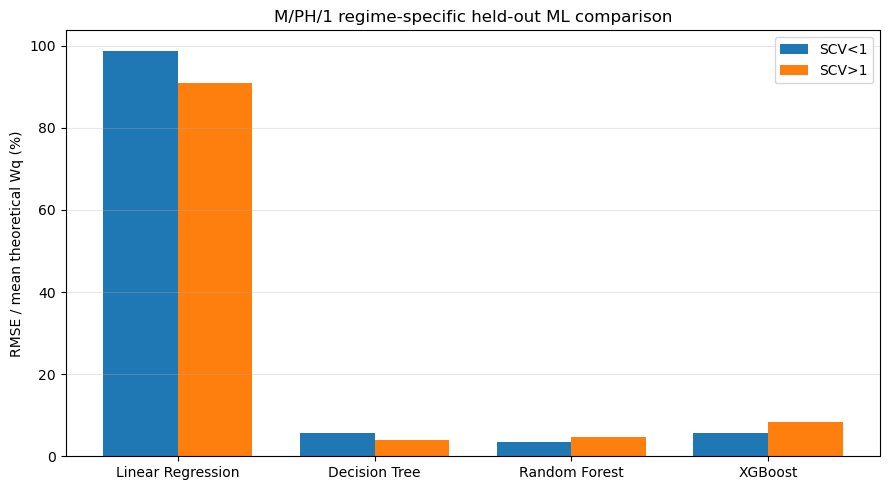

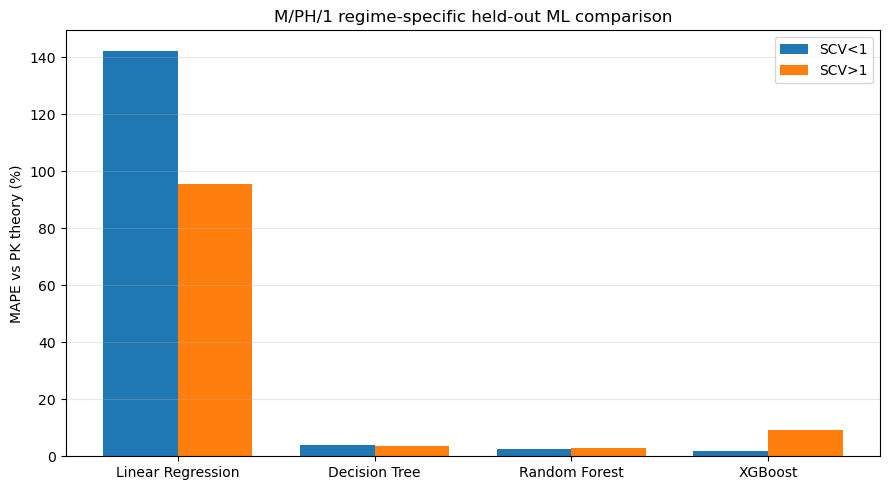

In [42]:
# NRMSE(mean) and MAPE are emphasized because the two regimes have
# different Wq scales.

model_order = list(short_names.keys())
x = np.arange(len(model_order))
width = 0.38

for metric, ylabel, filename in [
    (
        "NRMSE_mean_pct",
        "RMSE / mean theoretical Wq (%)",
        "mph1_low_vs_high_scv_nrmse_mean_comparison.png",
    ),
    (
        "MAPE_pct",
        "MAPE vs PK theory (%)",
        "mph1_low_vs_high_scv_mape_comparison.png",
    ),
]:
    fig, ax = plt.subplots(figsize=(9, 5))

    low_vals = [
        scv_regime_ml_comparison.loc[
            (scv_regime_ml_comparison["Regime"] == "SCV<1")
            & (scv_regime_ml_comparison["Model"] == model),
            metric,
        ].iloc[0]
        for model in model_order
    ]
    high_vals = [
        scv_regime_ml_comparison.loc[
            (scv_regime_ml_comparison["Regime"] == "SCV>1")
            & (scv_regime_ml_comparison["Model"] == model),
            metric,
        ].iloc[0]
        for model in model_order
    ]

    ax.bar(x - width / 2, low_vals, width, label="SCV<1")
    ax.bar(x + width / 2, high_vals, width, label="SCV>1")

    ax.set_xticks(x)
    ax.set_xticklabels(model_order)
    ax.set_ylabel(ylabel)
    ax.set_title("M/PH/1 regime-specific held-out ML comparison")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
